# IPL Cricket Performance Analytics — Complete EDA
### Capstone Project
### Datasets: matches.csv | deliveries.csv | players.csv | seasons.csv | fan_trends.csv
---

## Section 1 — Data Import, Initial Exploration & Quality Audit

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams.update({'figure.dpi': 100, 'axes.titlesize': 13, 'axes.titleweight': 'bold'})

# ── Load datasets ──
matches   = pd.read_csv('matches.csv')
deliveries= pd.read_csv('deliveries.csv')
players   = pd.read_csv('players.csv')
seasons   = pd.read_csv('seasons.csv')
fan_trends= pd.read_csv('fan_trends.csv')

print(' All datasets loaded successfully.')
print(f'  matches   : {matches.shape}')
print(f'  deliveries: {deliveries.shape}')
print(f'  players   : {players.shape}')
print(f'  seasons   : {seasons.shape}')
print(f'  fan_trends: {fan_trends.shape}')
print(f'\n  Total records: {matches.shape[0]+deliveries.shape[0]+players.shape[0]+seasons.shape[0]+fan_trends.shape[0]:,}')

 All datasets loaded successfully.
  matches   : (1158, 25)
  deliveries: (134190, 18)
  players   : (580, 12)
  seasons   : (18, 14)
  fan_trends: (4320, 25)

  Total records: 140,266


In [2]:
# ── Structured audit for each dataset ─────────────────────────────────────
def audit(df, name):
    print(f'\n{'='*60}')
    print(f'  DATASET: {name}')
    print(f'{'='*60}')
    print(f'Shape          : {df.shape[0]:,} rows × {df.shape[1]} cols')
    print(f'Duplicate rows : {df.duplicated().sum()}')
    print('\nMissing values:')
    miss = df.isnull().sum()
    miss = miss[miss > 0]
    if len(miss):
        for col, n in miss.items():
            print(f'  {col:<35} {n:>6}  ({n/len(df)*100:.1f}%)')
    else:
        print('  None')
    print('\nUnique values per column:')
    print(df.nunique().to_string())
    print('\nStatistical summary:')
    print(df.describe(include='all').to_string())

for df, name in [(matches,'matches'),(deliveries,'deliveries'),
                 (players,'players'),(seasons,'seasons'),(fan_trends,'fan_trends')]:
    audit(df, name)


  DATASET: matches
Shape          : 1,158 rows × 25 cols
Duplicate rows : 0

Missing values:
  winner                                  26  (2.2%)
  win_by                                  26  (2.2%)

Unique values per column:
match_id                  1158
season                      18
match_number                74
stage                        5
date                      1158
venue                       18
city                        17
team1                       17
team2                       17
toss_winner                 17
toss_decision                2
first_innings_score        203
first_innings_wickets       10
first_innings_overs         42
second_innings_score       179
second_innings_wickets      11
second_innings_overs        52
result                       3
winner                      17
win_by                       3
win_margin                  86
player_of_match            496
umpire1                     20
umpire2                     20
is_day_night                 

## Section 2 — Data Cleaning & Transformation

In [3]:
# ── Fix data types ────────────────────────────────────────────────────────
matches['date']   = pd.to_datetime(matches['date'])
matches['season'] = matches['season'].astype(int)

# ── Handle missing values — context-aware ─────────────────────────────────
cat_cols = ['extra_type', 'dismissal_type', 'dismissed_player', 'fielder']
deliveries[cat_cols] = deliveries[cat_cols].fillna('None')

players['bowling_style'] = players['bowling_style'].fillna('Non-Bowler')

# ── Feature engineering ───────────────────────────────────────────────────
# deliveries
deliveries['is_boundary'] = deliveries['batsman_runs'].isin([4, 6]).astype(int)
deliveries['is_six']      = (deliveries['batsman_runs'] == 6).astype(int)
deliveries['is_four']     = (deliveries['batsman_runs'] == 4).astype(int)
deliveries['over_cluster']= pd.cut(deliveries['over'],
                                    bins=[0,6,15,20],
                                    labels=['Powerplay','Middle','Death'])

# matches
matches['match_year']     = matches['date'].dt.year
matches['run_rate_diff']  = matches['first_innings_score'] - matches['second_innings_score']
matches['chased_successfully'] = (matches['win_by'] == 'wickets')

# players
players['career_length']  = players['last_season_played'] - players['ipl_debut_season']
players['price_growth']   = players['highest_auction_price_lakh'] - players['base_price_lakh']

# fan_trends
fan_trends['engagement_tier'] = pd.cut(
    fan_trends['engagement_rate'],
    bins=[0, 5, 15, 30, 100],
    labels=['Low', 'Medium', 'High', 'Viral'])
# month ordering
month_order = ['January','February','March','April','May','June',
               'July','August','September','October','November','December']
fan_trends['month'] = pd.Categorical(fan_trends['month'], categories=month_order, ordered=True)

print(' Cleaning & feature engineering complete.')
print(f'  New columns in deliveries : is_boundary, is_six, is_four, over_cluster')
print(f'  New columns in matches    : match_year, run_rate_diff, chased_successfully')
print(f'  New columns in players    : career_length, price_growth')
print(f'  New columns in fan_trends : engagement_tier')

 Cleaning & feature engineering complete.
  New columns in deliveries : is_boundary, is_six, is_four, over_cluster
  New columns in matches    : match_year, run_rate_diff, chased_successfully
  New columns in players    : career_length, price_growth
  New columns in fan_trends : engagement_tier


In [4]:
# ── Save cleaned versions ─────────────────────────────────────────────────
matches.to_csv('matches_clean.csv',     index=False)
deliveries.to_csv('deliveries_clean.csv', index=False)
players.to_csv('players_clean.csv',     index=False)
seasons.to_csv('seasons_clean.csv',     index=False)
fan_trends.to_csv('fan_trends_clean.csv', index=False)
print('Cleaned CSVs saved.')

Cleaned CSVs saved.


## Section 3 — Univariate Analysis (Single Variable Deep-Dives)

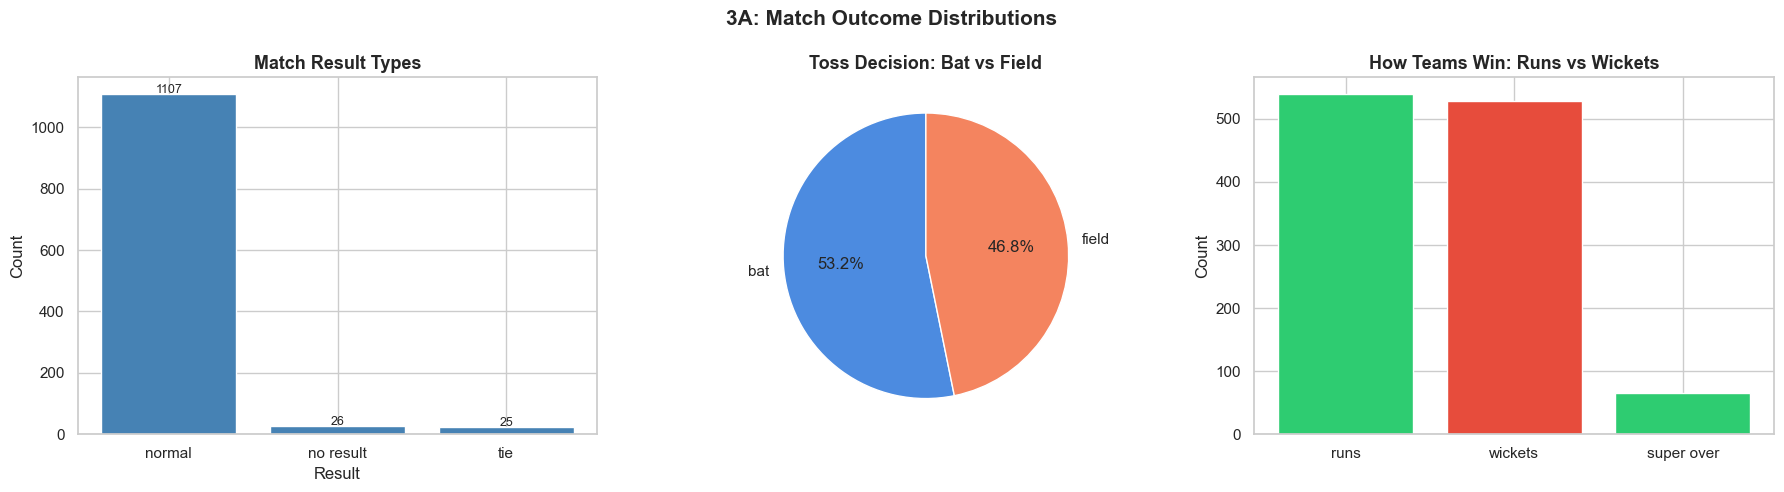


Insight: bat is the preferred toss choice (53.2% of matches)


In [5]:
# 3A — Match Outcome Distributions
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('3A: Match Outcome Distributions', fontsize=15, fontweight='bold')

# Result types
result_vc = matches['result'].value_counts()
axes[0].bar(result_vc.index, result_vc.values, color='steelblue', edgecolor='white')
axes[0].set_title('Match Result Types')
axes[0].set_xlabel('Result')
axes[0].set_ylabel('Count')
for i,(v) in enumerate(result_vc.values):
    axes[0].text(i, v+3, str(v), ha='center', fontsize=9)

# Toss decision pie
toss_vc = matches['toss_decision'].value_counts()
axes[1].pie(toss_vc.values, labels=toss_vc.index, autopct='%1.1f%%',
            colors=['#4C8BE0','#F4845F'], startangle=90)
axes[1].set_title('Toss Decision: Bat vs Field')

# Win method
wm_vc = matches['win_by'].value_counts()
axes[2].bar(wm_vc.index, wm_vc.values, color=['#2ECC71','#E74C3C'], edgecolor='white')
axes[2].set_title('How Teams Win: Runs vs Wickets')
axes[2].set_ylabel('Count')

plt.tight_layout()
plt.savefig('plot_3A_match_outcomes.png', bbox_inches='tight')
plt.show()
print(f'\nInsight: {toss_vc.idxmax()} is the preferred toss choice ({toss_vc.max()/toss_vc.sum()*100:.1f}% of matches)')

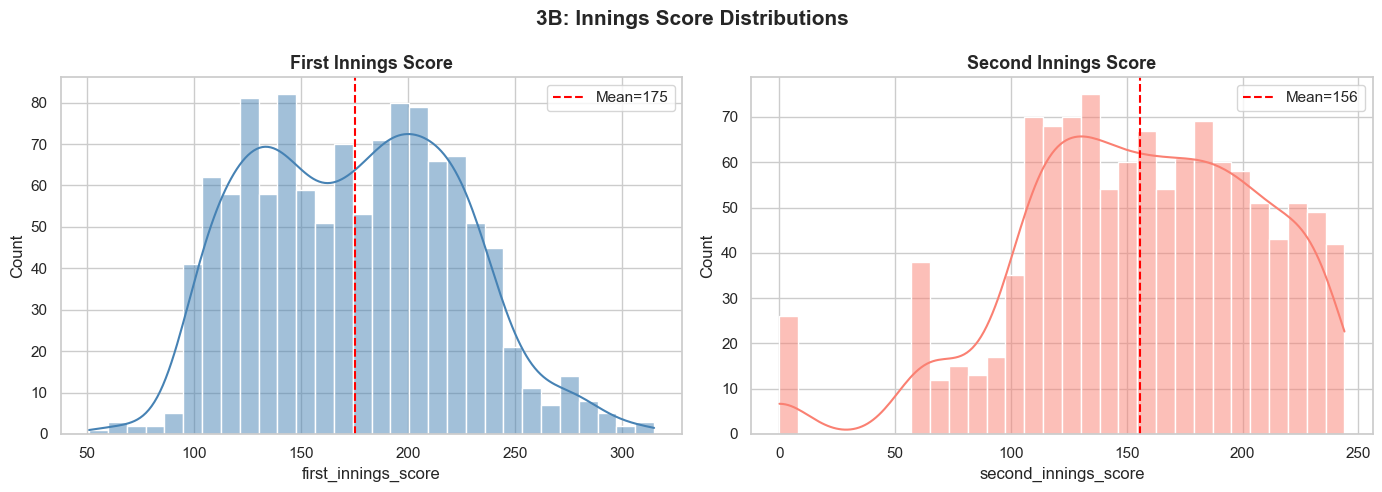

First innings  — Mean: 175.1 | Median: 176.0 | Std: 47.5
Second innings — Mean: 155.8 | Median: 157.0


In [6]:
# 3B — Scoring Distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('3B: Innings Score Distributions', fontsize=15, fontweight='bold')

sns.histplot(matches['first_innings_score'],  bins=30, kde=True, color='steelblue',  ax=axes[0])
axes[0].set_title('First Innings Score')
axes[0].axvline(matches['first_innings_score'].mean(),  color='red', ls='--',
                label=f"Mean={matches['first_innings_score'].mean():.0f}")
axes[0].legend()

sns.histplot(matches['second_innings_score'], bins=30, kde=True, color='salmon',    ax=axes[1])
axes[1].set_title('Second Innings Score')
axes[1].axvline(matches['second_innings_score'].mean(), color='red', ls='--',
                label=f"Mean={matches['second_innings_score'].mean():.0f}")
axes[1].legend()

plt.tight_layout()
plt.savefig('plot_3B_score_dist.png', bbox_inches='tight')
plt.show()

print(f'First innings  — Mean: {matches["first_innings_score"].mean():.1f} | Median: {matches["first_innings_score"].median():.1f} | Std: {matches["first_innings_score"].std():.1f}')
print(f'Second innings — Mean: {matches["second_innings_score"].mean():.1f} | Median: {matches["second_innings_score"].median():.1f}')

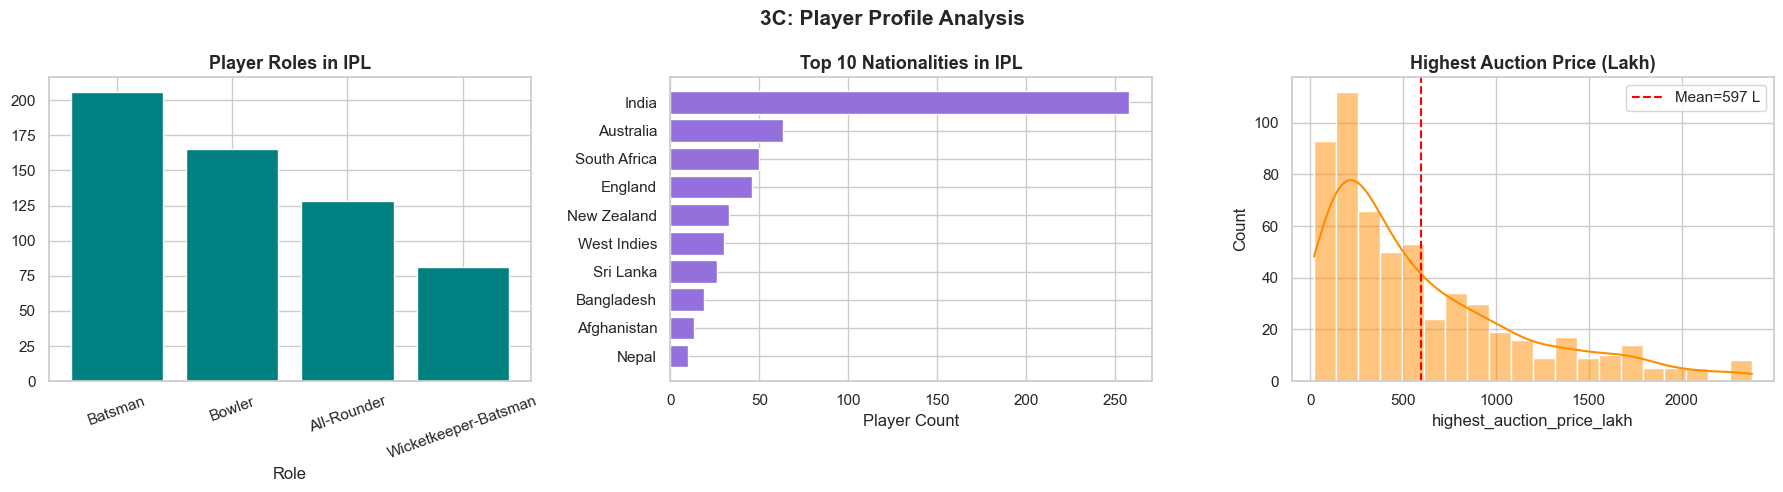

Most common role: Batsman (206 players)
Most common nationality: India (258 players)
Avg highest auction price: ₹597 Lakh


In [7]:
# 3C — Player Profile Analysis
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('3C: Player Profile Analysis', fontsize=15, fontweight='bold')

# Playing role
role_vc = players['playing_role'].value_counts()
axes[0].bar(role_vc.index, role_vc.values, color='teal', edgecolor='white')
axes[0].set_title('Player Roles in IPL')
axes[0].set_xlabel('Role')
axes[0].tick_params(axis='x', rotation=20)

# Top nationalities
nat_vc = players['nationality'].value_counts().head(10)
axes[1].barh(nat_vc.index[::-1], nat_vc.values[::-1], color='mediumpurple')
axes[1].set_title('Top 10 Nationalities in IPL')
axes[1].set_xlabel('Player Count')

# Auction price distribution
sns.histplot(players['highest_auction_price_lakh'], bins=20, kde=True, color='darkorange', ax=axes[2])
axes[2].set_title('Highest Auction Price (Lakh)')
axes[2].axvline(players['highest_auction_price_lakh'].mean(), color='red', ls='--',
                label=f"Mean={players['highest_auction_price_lakh'].mean():.0f} L")
axes[2].legend()

plt.tight_layout()
plt.savefig('plot_3C_player_profiles.png', bbox_inches='tight')
plt.show()

print(f'Most common role: {role_vc.idxmax()} ({role_vc.max()} players)')
print(f'Most common nationality: {nat_vc.idxmax()} ({nat_vc.max()} players)')
print(f'Avg highest auction price: ₹{players["highest_auction_price_lakh"].mean():.0f} Lakh')

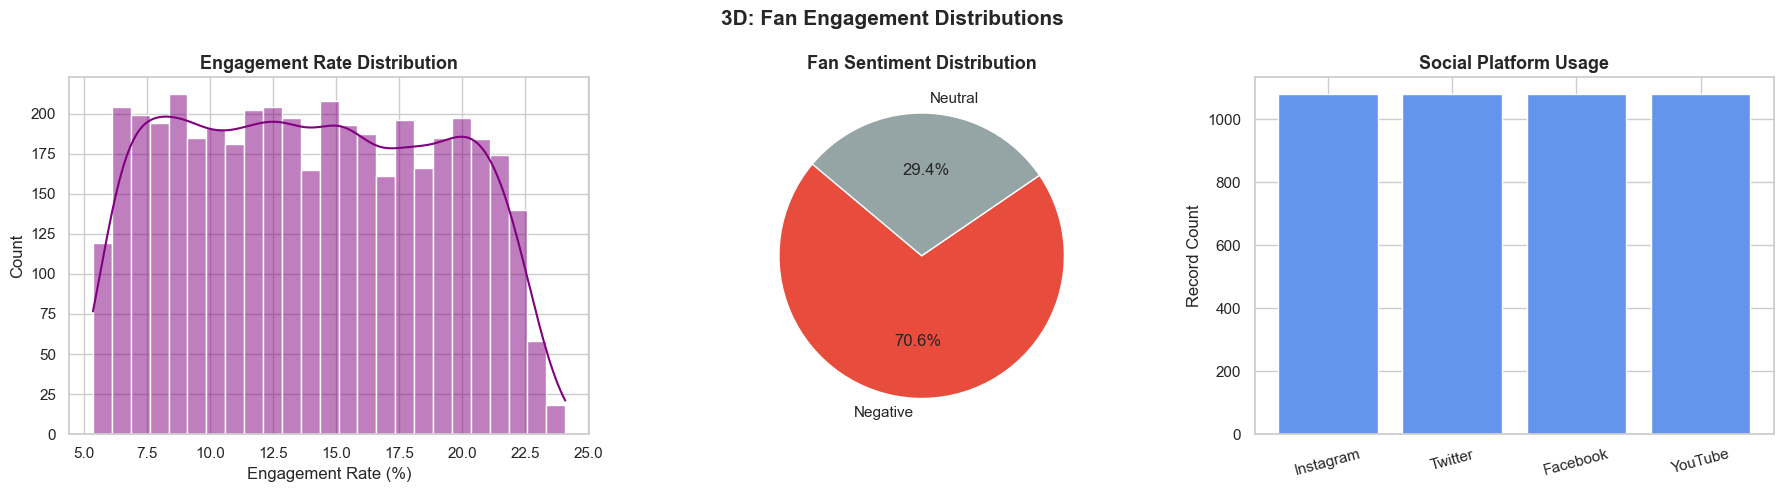

Dominant sentiment : Negative (70.6%)
Most used platform : Instagram
Avg engagement rate: 14.04%


In [8]:
# 3D — Fan Engagement Distributions
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('3D: Fan Engagement Distributions', fontsize=15, fontweight='bold')

sns.histplot(fan_trends['engagement_rate'], bins=25, kde=True, color='purple', ax=axes[0])
axes[0].set_title('Engagement Rate Distribution')
axes[0].set_xlabel('Engagement Rate (%)')

sent_vc = fan_trends['fan_sentiment'].value_counts()
colors_sent = {'Positive':'#2ECC71','Negative':'#E74C3C','Neutral':'#95A5A6'}
axes[1].pie(sent_vc.values, labels=sent_vc.index, autopct='%1.1f%%',
            colors=[colors_sent.get(s,'grey') for s in sent_vc.index], startangle=140)
axes[1].set_title('Fan Sentiment Distribution')

plat_vc = fan_trends['platform'].value_counts()
axes[2].bar(plat_vc.index, plat_vc.values, color='cornflowerblue', edgecolor='white')
axes[2].set_title('Social Platform Usage')
axes[2].set_ylabel('Record Count')
axes[2].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.savefig('plot_3D_fan_dist.png', bbox_inches='tight')
plt.show()

print(f'Dominant sentiment : {sent_vc.idxmax()} ({sent_vc.max()/sent_vc.sum()*100:.1f}%)')
print(f'Most used platform : {plat_vc.idxmax()}')
print(f'Avg engagement rate: {fan_trends["engagement_rate"].mean():.2f}%')

## Section 4 — Bivariate Analysis (Relationship Between Two Variables)

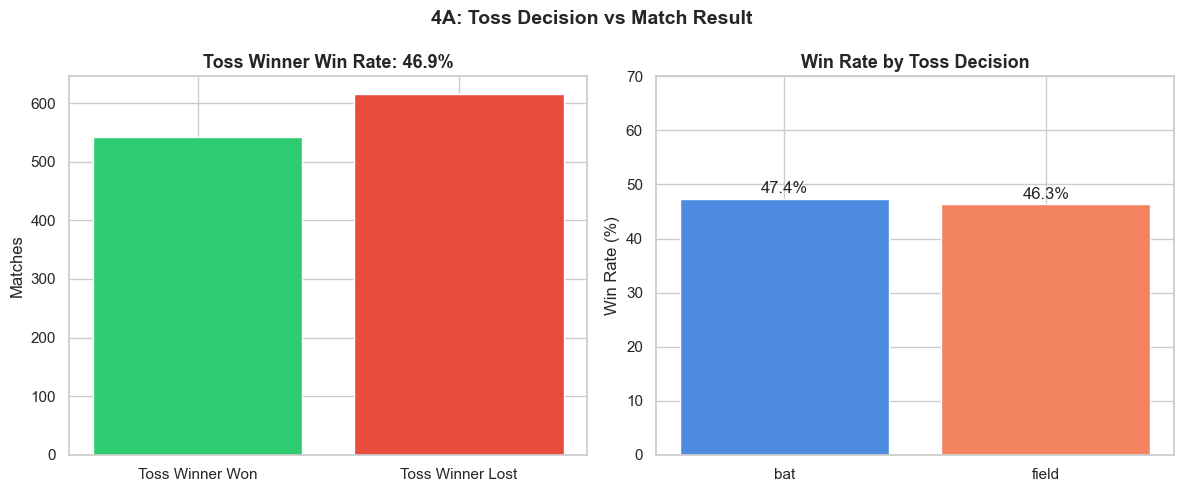

Toss winner wins 46.9% of matches (vs 50% random baseline)


In [9]:
# 4A — Toss Decision vs Match Result
toss_wins  = (matches['toss_winner'] == matches['winner']).sum()
total_m    = len(matches)
pct        = toss_wins / total_m * 100

toss_win_rate = matches.groupby('toss_decision').apply(
    lambda d: (d['toss_winner'] == d['winner']).mean() * 100
).reset_index(name='win_rate_pct')

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('4A: Toss Decision vs Match Result', fontsize=14, fontweight='bold')

axes[0].bar(['Toss Winner Won', 'Toss Winner Lost'],
            [toss_wins, total_m - toss_wins],
            color=['#2ECC71','#E74C3C'], edgecolor='white')
axes[0].set_title(f'Toss Winner Win Rate: {pct:.1f}%')
axes[0].set_ylabel('Matches')

axes[1].bar(toss_win_rate['toss_decision'], toss_win_rate['win_rate_pct'],
            color=['#4C8BE0','#F4845F'], edgecolor='white')
axes[1].set_title('Win Rate by Toss Decision')
axes[1].set_ylabel('Win Rate (%)')
axes[1].set_ylim(0, 70)
for i, row in toss_win_rate.iterrows():
    axes[1].text(i, row['win_rate_pct']+1, f'{row["win_rate_pct"]:.1f}%', ha='center')

plt.tight_layout()
plt.savefig('plot_4A_toss_result.png', bbox_inches='tight')
plt.show()
print(f'Toss winner wins {pct:.1f}% of matches (vs 50% random baseline)')

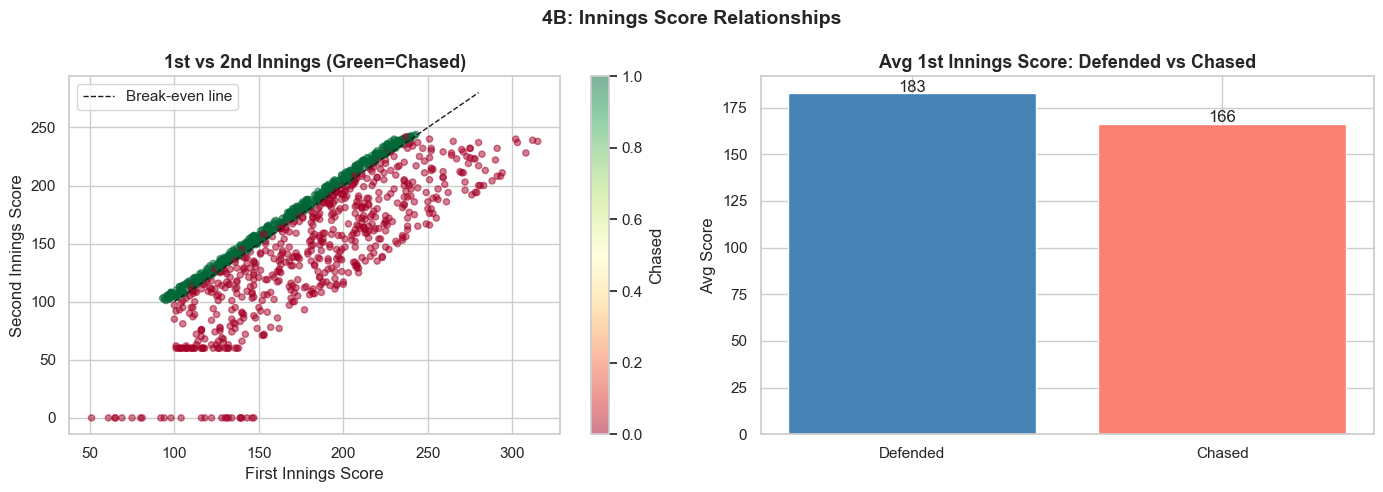

In [10]:
# 4B — First Innings Score vs Second Innings Score
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('4B: Innings Score Relationships', fontsize=14, fontweight='bold')

sc = axes[0].scatter(matches['first_innings_score'], matches['second_innings_score'],
                     c=matches['chased_successfully'].astype(int),
                     cmap='RdYlGn', alpha=0.5, s=20)
axes[0].set_xlabel('First Innings Score')
axes[0].set_ylabel('Second Innings Score')
axes[0].set_title('1st vs 2nd Innings (Green=Chased)')
axes[0].plot([100, 280],[100, 280], 'k--', lw=1, label='Break-even line')
plt.colorbar(sc, ax=axes[0], label='Chased')
axes[0].legend()

avg_first_by_result = matches.groupby('chased_successfully')['first_innings_score'].mean()
avg_first_by_result.index = ['Defended','Chased']
axes[1].bar(avg_first_by_result.index, avg_first_by_result.values,
            color=['steelblue','salmon'], edgecolor='white')
axes[1].set_title('Avg 1st Innings Score: Defended vs Chased')
axes[1].set_ylabel('Avg Score')
for i, v in enumerate(avg_first_by_result.values):
    axes[1].text(i, v+1, f'{v:.0f}', ha='center')

plt.tight_layout()
plt.savefig('plot_4B_innings_scatter.png', bbox_inches='tight')
plt.show()

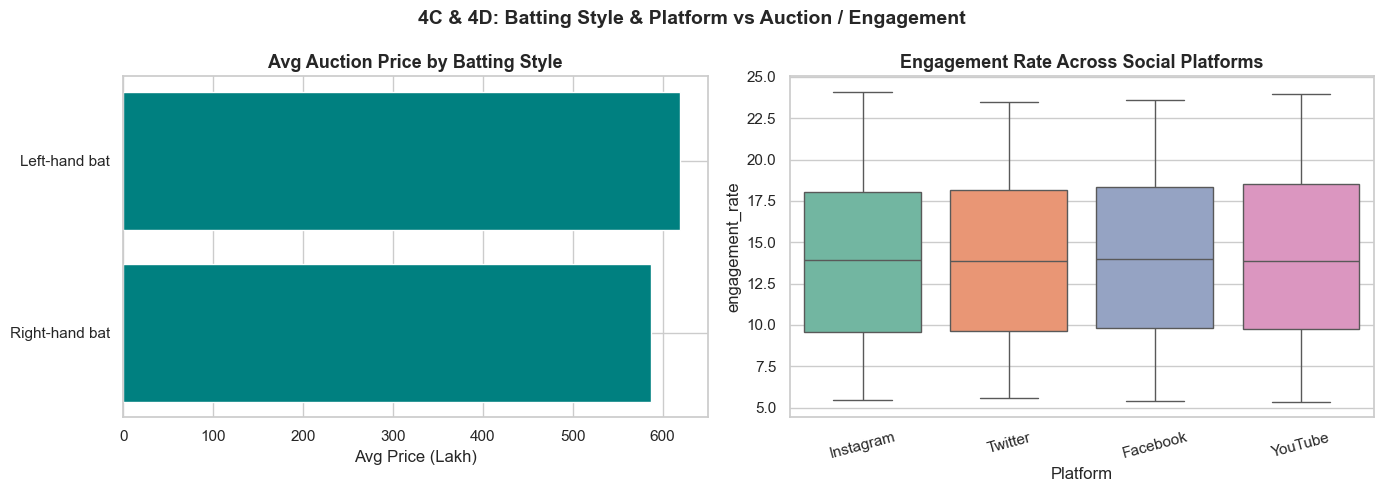


Avg engagement rate by platform:
platform
Facebook     14.10
YouTube      14.05
Instagram    14.02
Twitter      13.99
Name: engagement_rate, dtype: float64


In [11]:
# 4C — Batting Style vs Auction Price
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('4C & 4D: Batting Style & Platform vs Auction / Engagement', fontsize=14, fontweight='bold')

style_price = players.groupby('batting_style')['highest_auction_price_lakh'].mean().sort_values()
axes[0].barh(style_price.index, style_price.values, color='teal', edgecolor='white')
axes[0].set_title('Avg Auction Price by Batting Style')
axes[0].set_xlabel('Avg Price (Lakh)')

# 4D — Platform vs Engagement Rate
sns.boxplot(x='platform', y='engagement_rate', data=fan_trends, ax=axes[1], palette='Set2')
axes[1].set_title('Engagement Rate Across Social Platforms')
axes[1].set_xlabel('Platform')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.savefig('plot_4CD_price_engagement.png', bbox_inches='tight')
plt.show()

print('\nAvg engagement rate by platform:')
print(fan_trends.groupby('platform')['engagement_rate'].mean().sort_values(ascending=False).round(2))

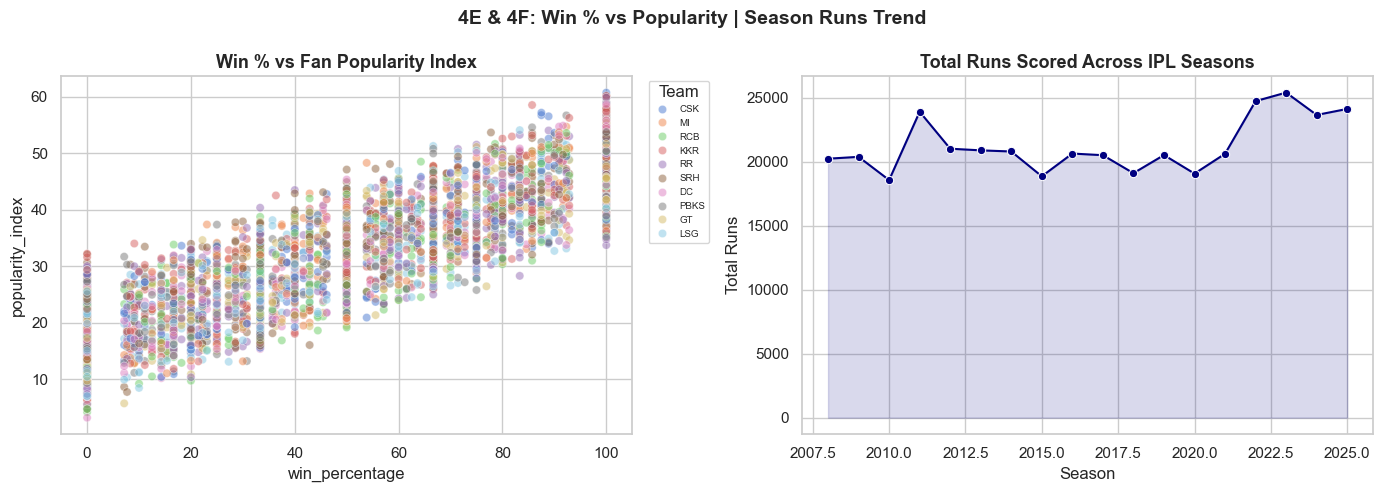


Correlation matrix (win% vs fan metrics):
                  win_percentage  popularity_index  engagement_rate
win_percentage             1.000             0.878            0.013
popularity_index           0.878             1.000            0.081
engagement_rate            0.013             0.081            1.000


In [12]:
# 4E — Win Percentage vs Fan Popularity Index
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('4E & 4F: Win % vs Popularity | Season Runs Trend', fontsize=14, fontweight='bold')

sns.scatterplot(x='win_percentage', y='popularity_index', hue='team',
                data=fan_trends, alpha=0.5, ax=axes[0])
axes[0].set_title('Win % vs Fan Popularity Index')
axes[0].legend(bbox_to_anchor=(1.02, 1), fontsize=7, title='Team')

# 4F — Season vs Total Runs
sns.lineplot(x='season', y='total_runs_scored', data=seasons, marker='o',
             color='navy', ax=axes[1])
axes[1].fill_between(seasons['season'], seasons['total_runs_scored'], alpha=0.15, color='navy')
axes[1].set_title('Total Runs Scored Across IPL Seasons')
axes[1].set_xlabel('Season')
axes[1].set_ylabel('Total Runs')

plt.tight_layout()
plt.savefig('plot_4EF_popularity_runs.png', bbox_inches='tight')
plt.show()

corr = fan_trends[['win_percentage','popularity_index','engagement_rate']].corr()
print('\nCorrelation matrix (win% vs fan metrics):')
print(corr.round(3))

## Section 5 — Multivariate Analysis (Three or More Variables Together)

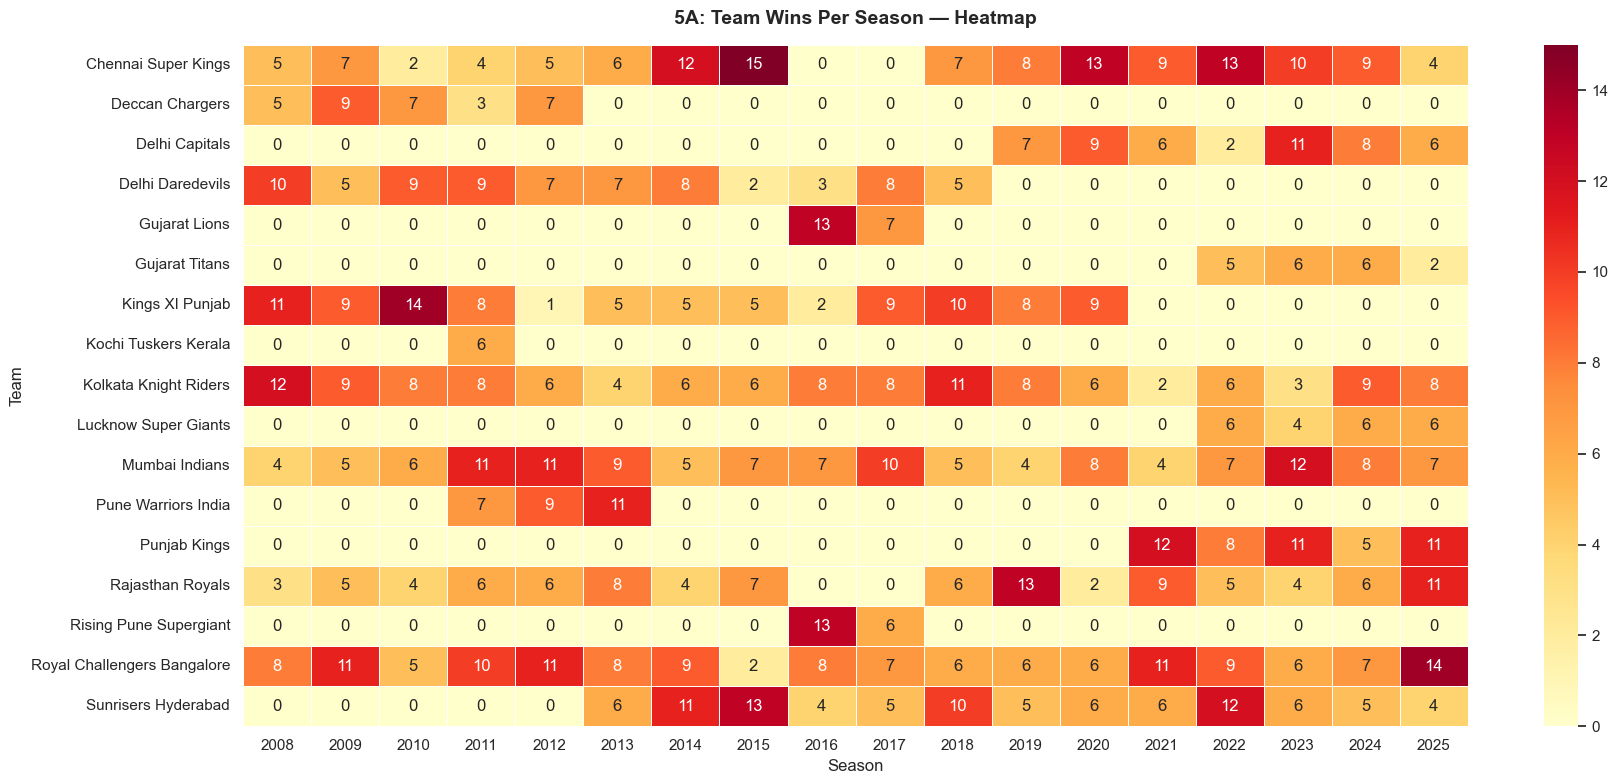

In [13]:
# 5A — Team Performance Heatmap by Season
team_season_wins = matches.groupby(['season', 'winner']).size().unstack(fill_value=0)

plt.figure(figsize=(18, 8))
sns.heatmap(team_season_wins.T, annot=True, fmt='d', cmap='YlOrRd',
            linewidths=0.5, linecolor='white')
plt.title('5A: Team Wins Per Season — Heatmap', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Season')
plt.ylabel('Team')
plt.tight_layout()
plt.savefig('plot_5A_team_season_heatmap.png', bbox_inches='tight')
plt.show()

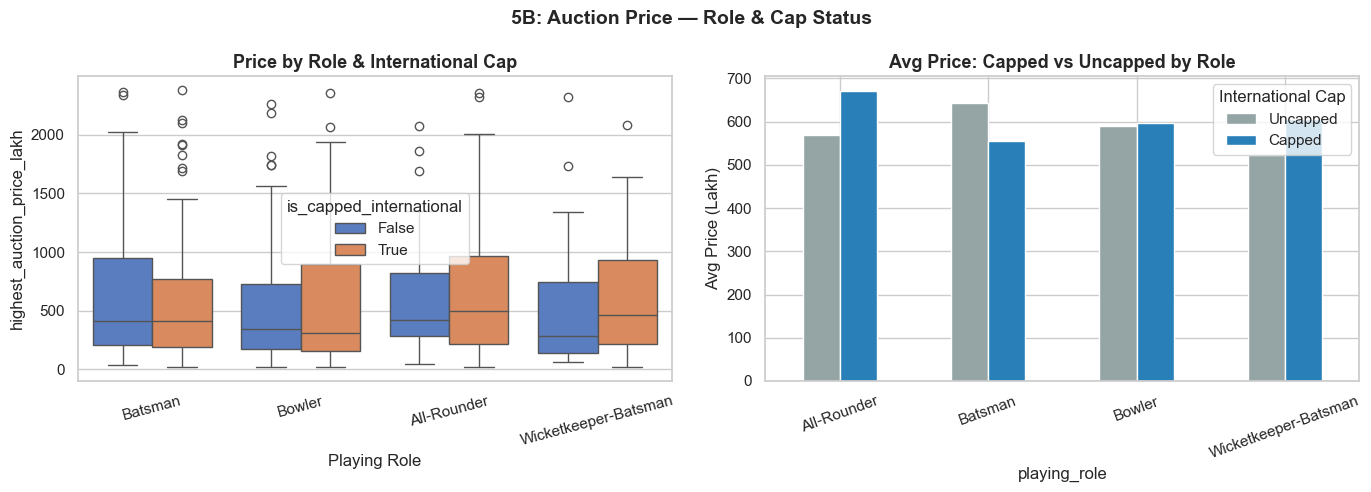

In [14]:
# 5B — Player Role × Cap Status × Auction Price
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('5B: Auction Price — Role & Cap Status', fontsize=14, fontweight='bold')

sns.boxplot(x='playing_role', y='highest_auction_price_lakh',
            hue='is_capped_international', data=players, ax=axes[0])
axes[0].set_title('Price by Role & International Cap')
axes[0].set_xlabel('Playing Role')
axes[0].tick_params(axis='x', rotation=15)

# Mean price grouped
role_cap = players.groupby(['playing_role','is_capped_international'])['highest_auction_price_lakh'].mean().unstack()
role_cap.columns = ['Uncapped','Capped']
role_cap.plot(kind='bar', ax=axes[1], color=['#95A5A6','#2980B9'], edgecolor='white')
axes[1].set_title('Avg Price: Capped vs Uncapped by Role')
axes[1].set_ylabel('Avg Price (Lakh)')
axes[1].tick_params(axis='x', rotation=20)
axes[1].legend(title='International Cap')

plt.tight_layout()
plt.savefig('plot_5B_player_role_cap.png', bbox_inches='tight')
plt.show()

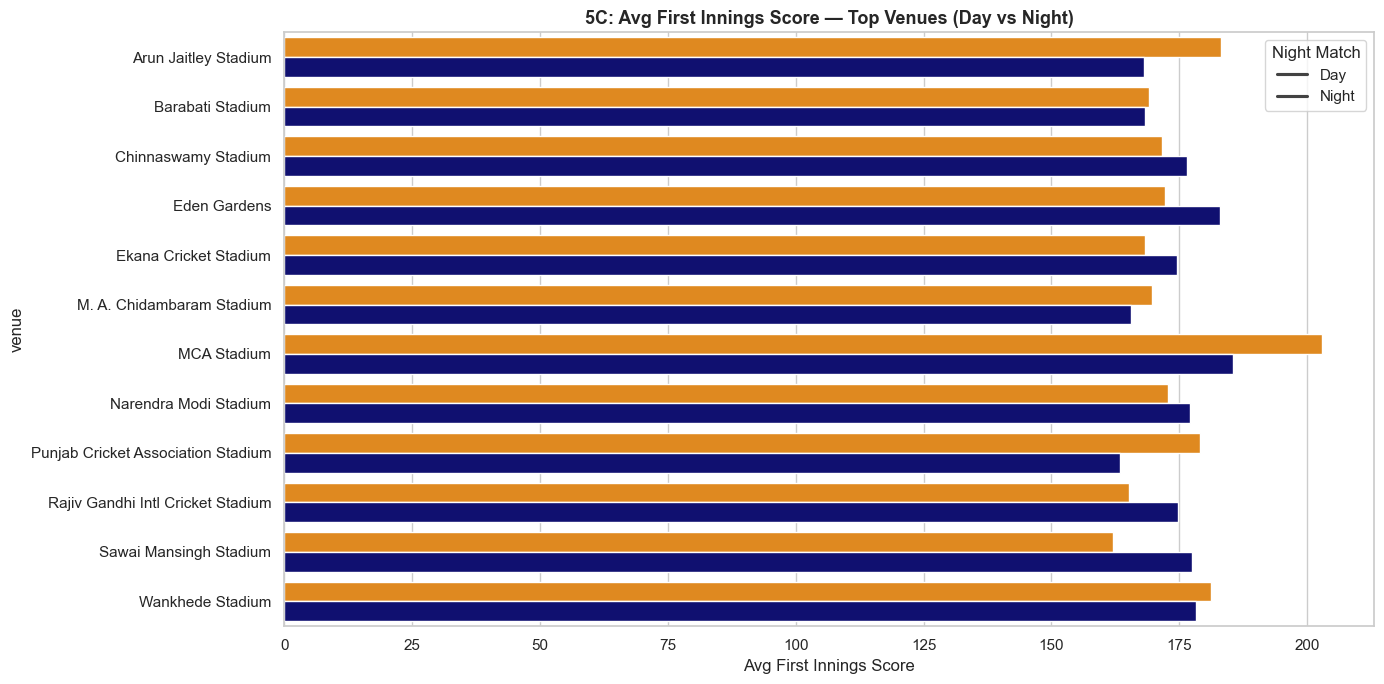

In [15]:
# 5C — Venue × Avg Score × Day/Night
venue_stats = matches.groupby(['venue', 'is_day_night']).agg(
    avg_first=('first_innings_score', 'mean'),
    match_count=('match_id','count')
).reset_index()

top_venues = venue_stats[venue_stats['match_count'] >= 8].copy()
# Keep top 12 by total matches
top_v_names = (top_venues.groupby('venue')['match_count'].sum()
               .sort_values(ascending=False).head(12).index)
top_venues = top_venues[top_venues['venue'].isin(top_v_names)]

plt.figure(figsize=(14, 7))
sns.barplot(x='avg_first', y='venue', hue='is_day_night', data=top_venues,
            palette={True:'navy', False:'darkorange'})
plt.title('5C: Avg First Innings Score — Top Venues (Day vs Night)', fontsize=13, fontweight='bold')
plt.xlabel('Avg First Innings Score')
plt.legend(title='Night Match', labels=['Day','Night'])
plt.tight_layout()
plt.savefig('plot_5C_venue_daynight.png', bbox_inches='tight')
plt.show()

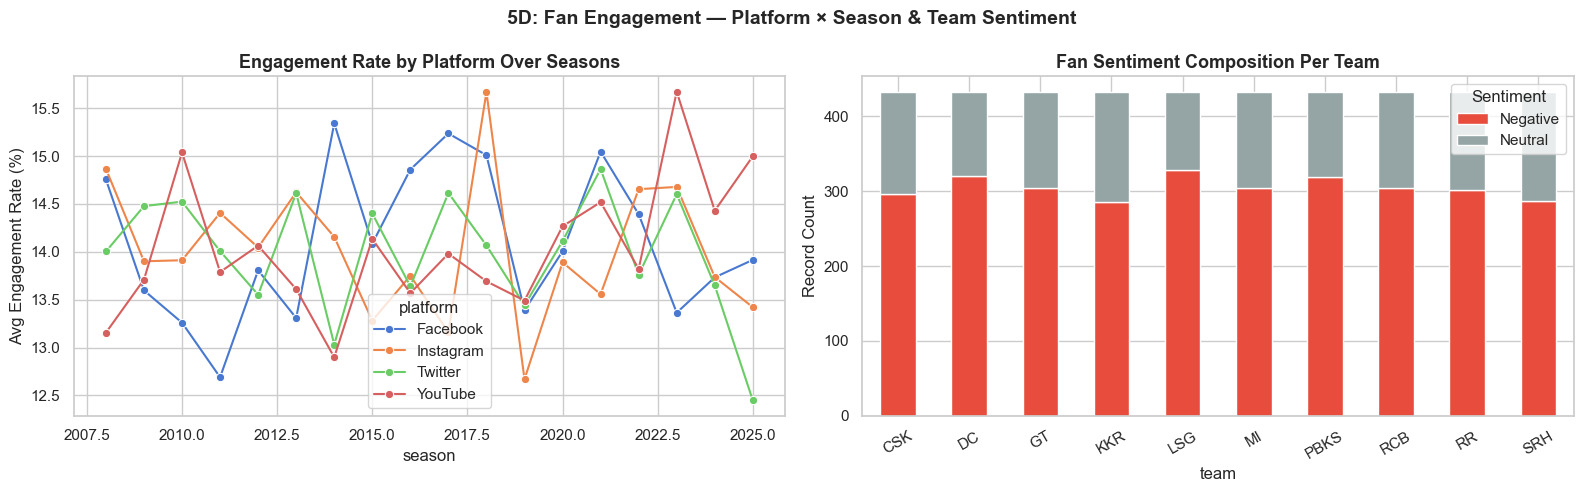

In [16]:
# 5D — Fan Trend: Platform × Season Engagement
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('5D: Fan Engagement — Platform × Season & Team Sentiment', fontsize=14, fontweight='bold')

plat_season = fan_trends.groupby(['season','platform'])['engagement_rate'].mean().reset_index()
sns.lineplot(x='season', y='engagement_rate', hue='platform',
             data=plat_season, marker='o', ax=axes[0])
axes[0].set_title('Engagement Rate by Platform Over Seasons')
axes[0].set_ylabel('Avg Engagement Rate (%)')

# Stacked: sentiment per team
sent_team = fan_trends.groupby(['team','fan_sentiment']).size().unstack(fill_value=0)
sent_team.plot(kind='bar', stacked=True, ax=axes[1],
               color=['#E74C3C','#95A5A6','#2ECC71'], edgecolor='white')
axes[1].set_title('Fan Sentiment Composition Per Team')
axes[1].set_ylabel('Record Count')
axes[1].tick_params(axis='x', rotation=30)
axes[1].legend(title='Sentiment')

plt.tight_layout()
plt.savefig('plot_5D_fan_multivariate.png', bbox_inches='tight')
plt.show()

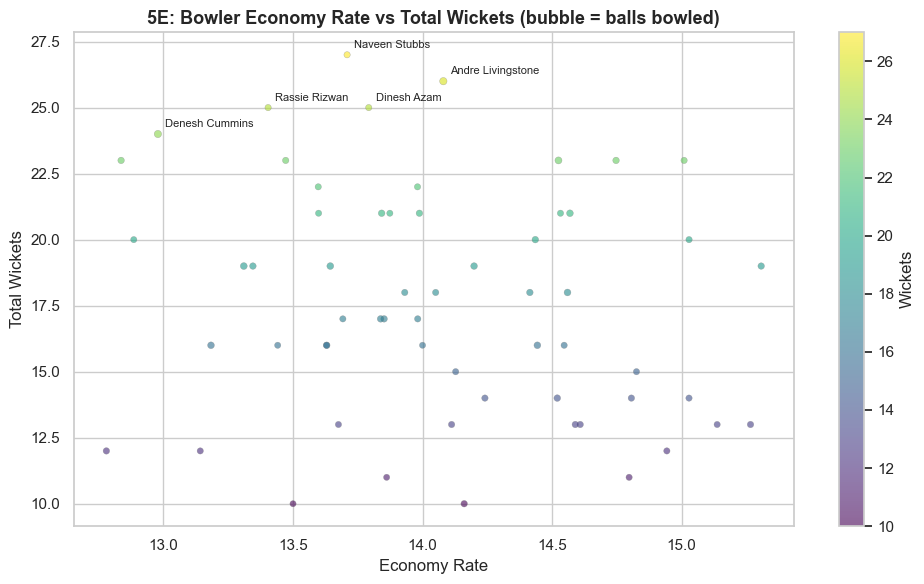

Top 10 bowlers (wickets):
           bowler  balls  runs_conceded  wickets   economy
    Naveen Stubbs    309            706       27 13.708738
Andre Livingstone    424            995       26 14.080189
      Dinesh Azam    308            708       25 13.792208
    Rassie Rizwan    312            697       25 13.403846
   Denesh Cummins    417            902       24 12.978417
      Kieron Pope    318            714       23 13.471698
 Najibullah Ngidi    330            706       23 12.836364
    Ruturaj Kumar    332            816       23 14.746988
        Sam Zaman    311            778       23 15.009646
      Steve Zaman    385            932       23 14.524675


In [17]:
# 5E — Bowler Economy vs Wickets
bowler_stats = deliveries.groupby('bowler').agg(
    balls=('ball','count'),
    runs_conceded=('total_runs','sum'),
    wickets=('is_wicket','sum')
).reset_index()
bowler_stats['economy']           = (bowler_stats['runs_conceded'] / bowler_stats['balls']) * 6
bowler_stats['wickets_per_over']  = (bowler_stats['wickets']       / bowler_stats['balls']) * 6
bowler_stats = bowler_stats[bowler_stats['balls'] >= 300]   # min 50 overs

plt.figure(figsize=(10, 6))
sc = plt.scatter(bowler_stats['economy'], bowler_stats['wickets'],
                 s=bowler_stats['balls']/15, alpha=0.6,
                 c=bowler_stats['wickets'], cmap='viridis', edgecolors='grey', lw=0.3)
plt.colorbar(sc, label='Wickets')
plt.xlabel('Economy Rate')
plt.ylabel('Total Wickets')
plt.title('5E: Bowler Economy Rate vs Total Wickets (bubble = balls bowled)',
          fontsize=13, fontweight='bold')

# Label top wicket-takers
top_bowlers = bowler_stats.nlargest(5, 'wickets')
for _, row in top_bowlers.iterrows():
    plt.annotate(row['bowler'], (row['economy'], row['wickets']),
                 textcoords='offset points', xytext=(5,5), fontsize=8)

plt.tight_layout()
plt.savefig('plot_5E_bowler_economy.png', bbox_inches='tight')
plt.show()

print('Top 10 bowlers (wickets):')
print(bowler_stats.nlargest(10,'wickets')[['bowler','balls','runs_conceded','wickets','economy']].to_string(index=False))

## Section 6 — Team Performance Analytics

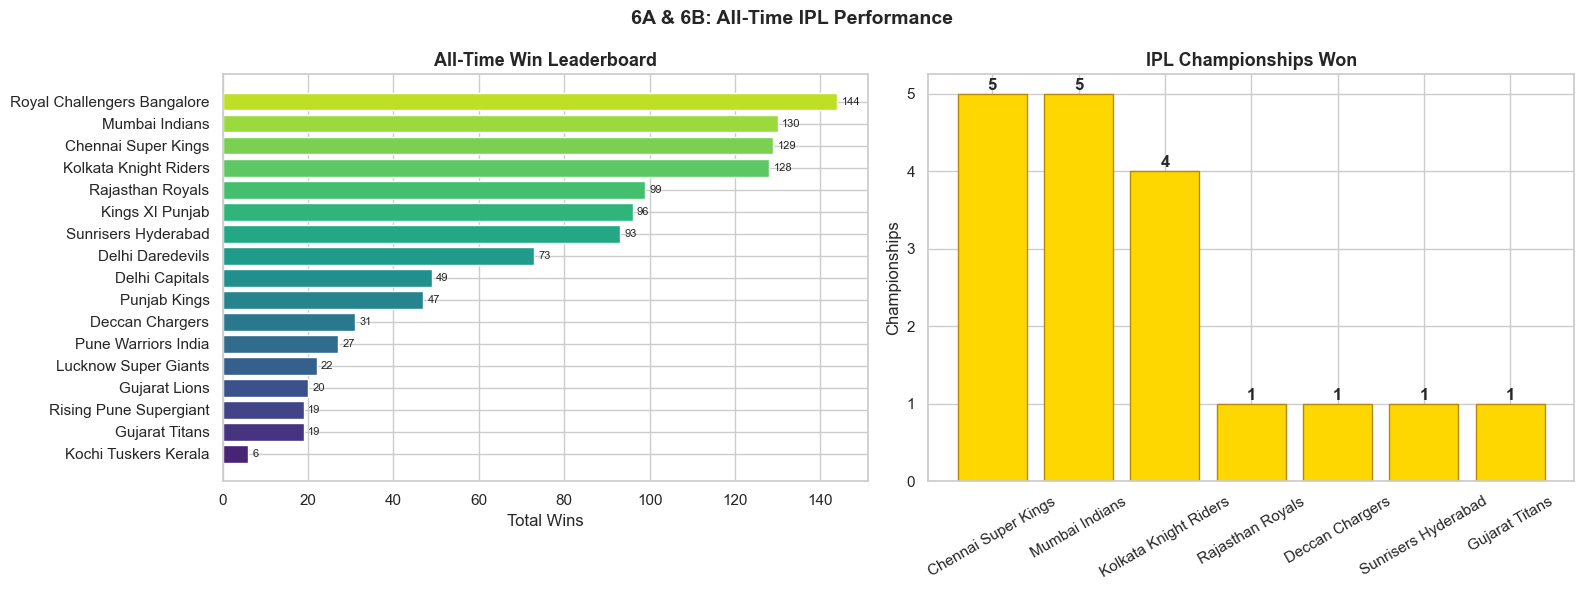

In [18]:
# 6A — All-time wins leaderboard
team_wins = matches['winner'].value_counts().reset_index()
team_wins.columns = ['team','wins']

# 6B — Championship count
champ_count = seasons['champion'].value_counts().reset_index()
champ_count.columns = ['team','championships']

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('6A & 6B: All-Time IPL Performance', fontsize=14, fontweight='bold')

colors = plt.cm.viridis_r(np.linspace(0.1, 0.9, len(team_wins)))
axes[0].barh(team_wins['team'][::-1], team_wins['wins'][::-1], color=colors[::-1])
axes[0].set_title('All-Time Win Leaderboard')
axes[0].set_xlabel('Total Wins')
for i, v in enumerate(team_wins['wins'][::-1]):
    axes[0].text(v+1, i, str(v), va='center', fontsize=8)

axes[1].bar(champ_count['team'], champ_count['championships'],
            color='gold', edgecolor='darkgoldenrod')
axes[1].set_title('IPL Championships Won')
axes[1].set_ylabel('Championships')
axes[1].tick_params(axis='x', rotation=30)
for i, v in enumerate(champ_count['championships']):
    axes[1].text(i, v+0.05, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('plot_6AB_team_wins_champ.png', bbox_inches='tight')
plt.show()

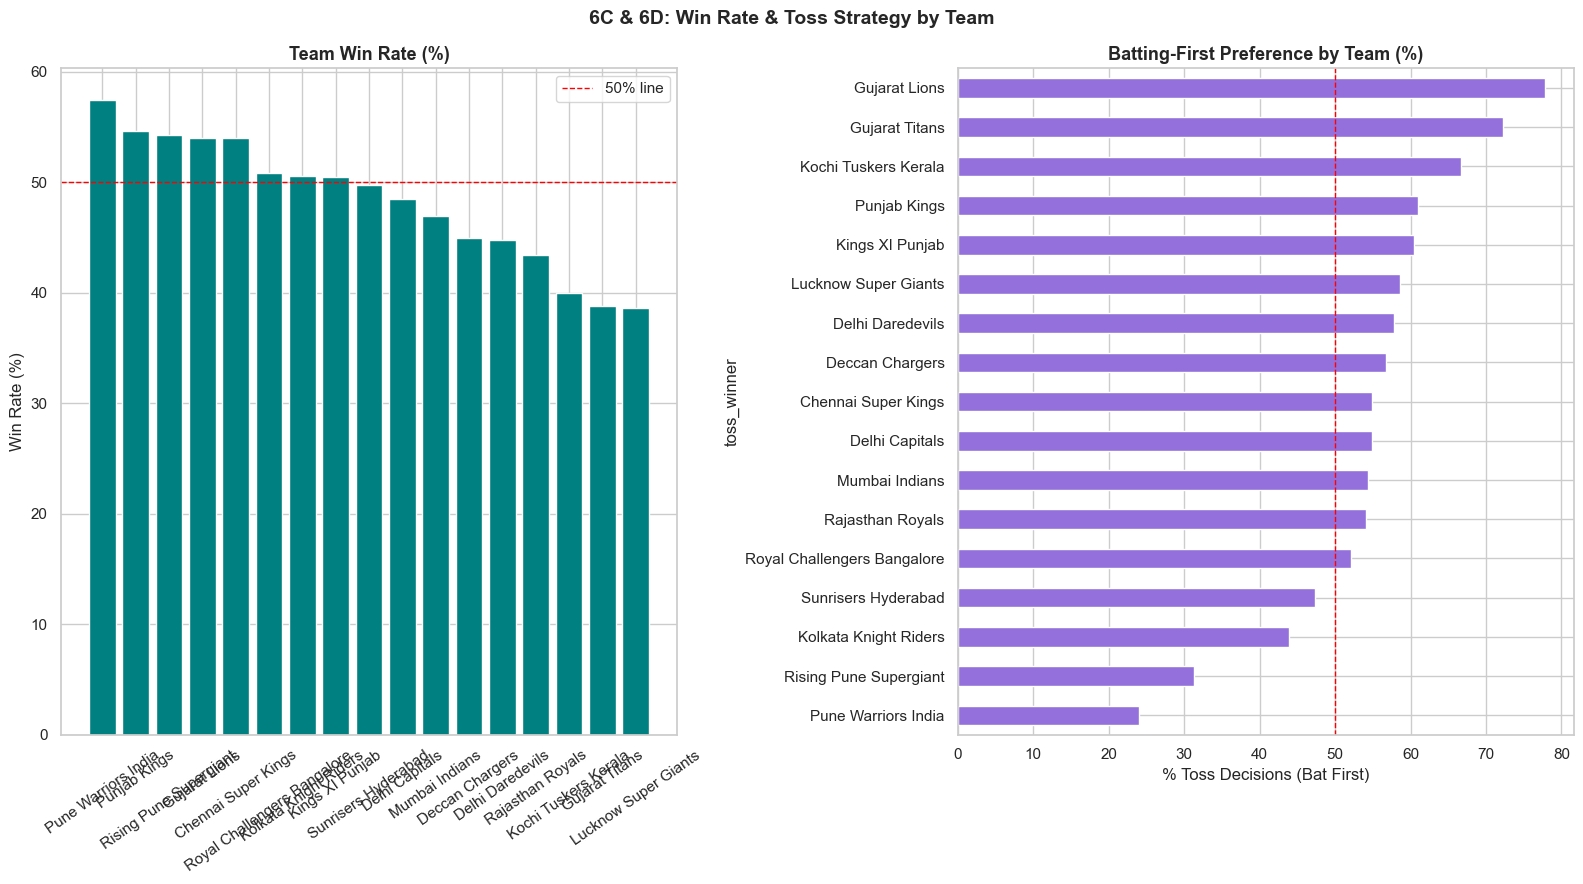

In [19]:
# 6C — Win rate per team  |  6D — Toss decision preference
total_per_team = pd.concat([matches['team1'], matches['team2']]).value_counts()
wins_per_team  = matches['winner'].value_counts()
win_rate = (wins_per_team / total_per_team * 100).dropna().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 9))
fig.suptitle('6C & 6D: Win Rate & Toss Strategy by Team', fontsize=14, fontweight='bold')

axes[0].bar(win_rate.index, win_rate.values, color='teal', edgecolor='white')
axes[0].set_title('Team Win Rate (%)')
axes[0].set_ylabel('Win Rate (%)')
axes[0].tick_params(axis='x', rotation=35)
axes[0].axhline(50, color='red', ls='--', lw=1, label='50% line')
axes[0].legend()

# Bat preference
team_toss = matches.groupby(['toss_winner','toss_decision']).size().unstack(fill_value=0)
if 'bat' in team_toss.columns and 'field' in team_toss.columns:
    team_toss['bat_pref'] = team_toss['bat'] / (team_toss['bat']+team_toss['field']) * 100
    team_toss['bat_pref'].sort_values().plot(kind='barh', ax=axes[1], color='mediumpurple')
    axes[1].set_title('Batting-First Preference by Team (%)')
    axes[1].set_xlabel('% Toss Decisions (Bat First)')
    axes[1].axvline(50, color='red', ls='--', lw=1)

plt.tight_layout()
plt.savefig('plot_6CD_winrate_toss.png', bbox_inches='tight')
plt.show()

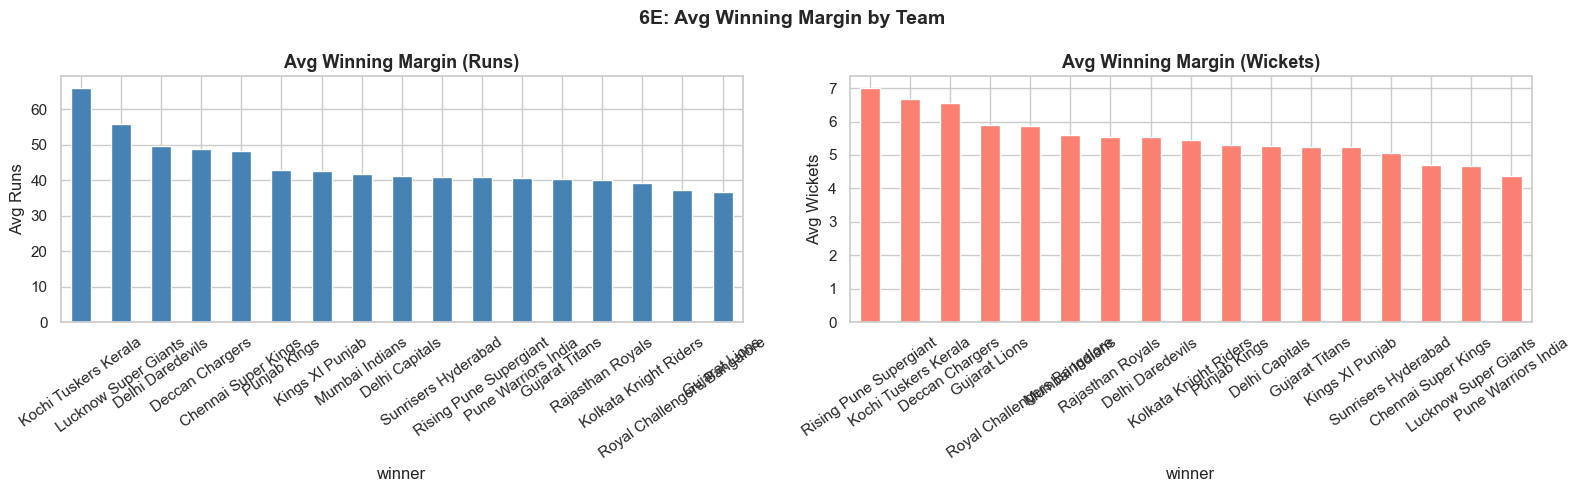

In [20]:
# 6E — Winning margin by team
runs_wins   = matches[matches['win_by']=='runs']
wicket_wins = matches[matches['win_by']=='wickets']

avg_margin_runs    = runs_wins.groupby('winner')['win_margin'].mean().sort_values(ascending=False)
avg_margin_wickets = wicket_wins.groupby('winner')['win_margin'].mean().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('6E: Avg Winning Margin by Team', fontsize=14, fontweight='bold')

avg_margin_runs.plot(kind='bar', ax=axes[0], color='steelblue', edgecolor='white')
axes[0].set_title('Avg Winning Margin (Runs)')
axes[0].set_ylabel('Avg Runs')
axes[0].tick_params(axis='x', rotation=35)

avg_margin_wickets.plot(kind='bar', ax=axes[1], color='salmon', edgecolor='white')
axes[1].set_title('Avg Winning Margin (Wickets)')
axes[1].set_ylabel('Avg Wickets')
axes[1].tick_params(axis='x', rotation=35)

plt.tight_layout()
plt.savefig('plot_6E_win_margins.png', bbox_inches='tight')
plt.show()

## Section 7 — Player Performance Analytics

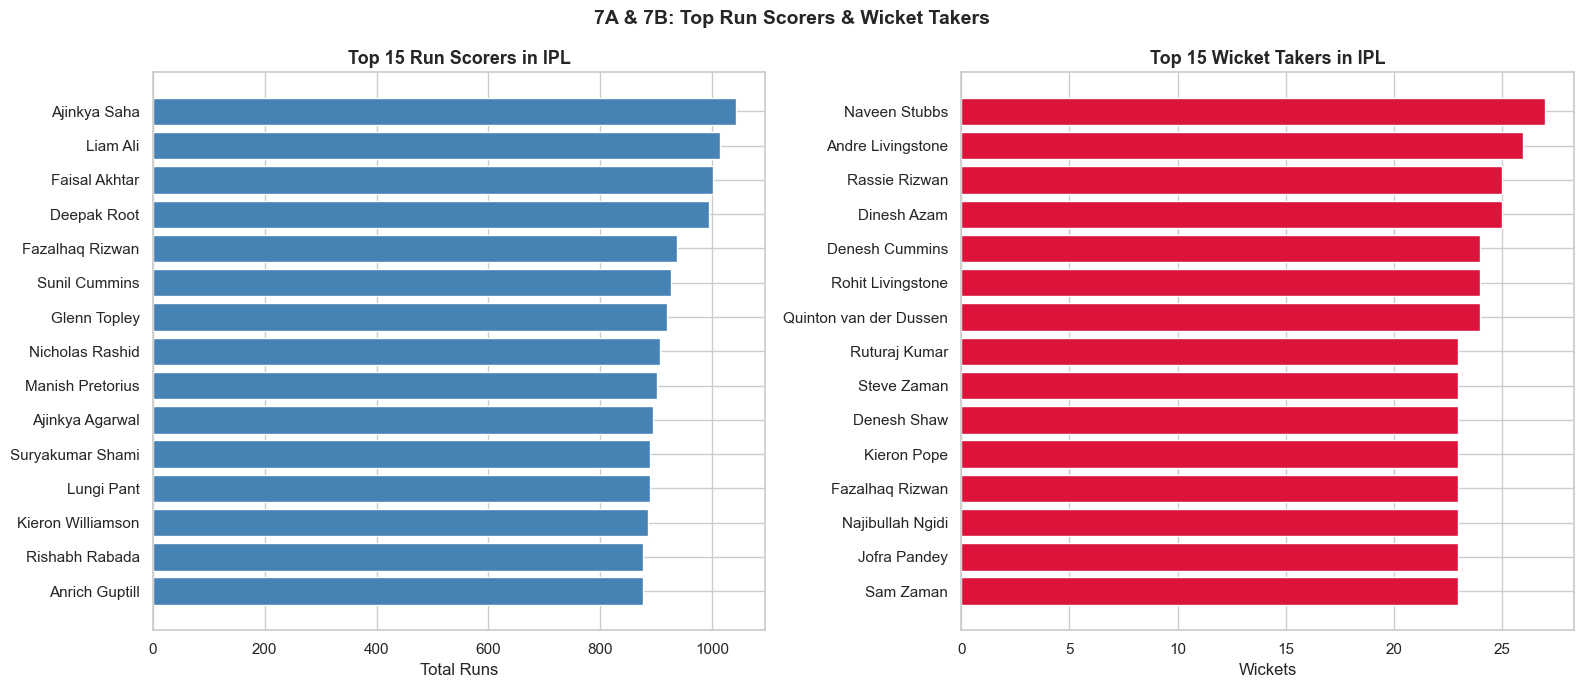

In [21]:
# 7A & 7B — Top run scorers & wicket takers
batsman_runs = deliveries.groupby('striker')['batsman_runs'].sum().sort_values(ascending=False)
wicket_df    = deliveries[deliveries['is_wicket']==True]
wicket_takers= wicket_df.groupby('bowler').size().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle('7A & 7B: Top Run Scorers & Wicket Takers', fontsize=14, fontweight='bold')

top15_bat = batsman_runs.head(15)
axes[0].barh(top15_bat.index[::-1], top15_bat.values[::-1], color='steelblue')
axes[0].set_title('Top 15 Run Scorers in IPL')
axes[0].set_xlabel('Total Runs')

top15_bowl = wicket_takers.head(15)
axes[1].barh(top15_bowl.index[::-1], top15_bowl.values[::-1], color='crimson')
axes[1].set_title('Top 15 Wicket Takers in IPL')
axes[1].set_xlabel('Wickets')

plt.tight_layout()
plt.savefig('plot_7AB_top_performers.png', bbox_inches='tight')
plt.show()

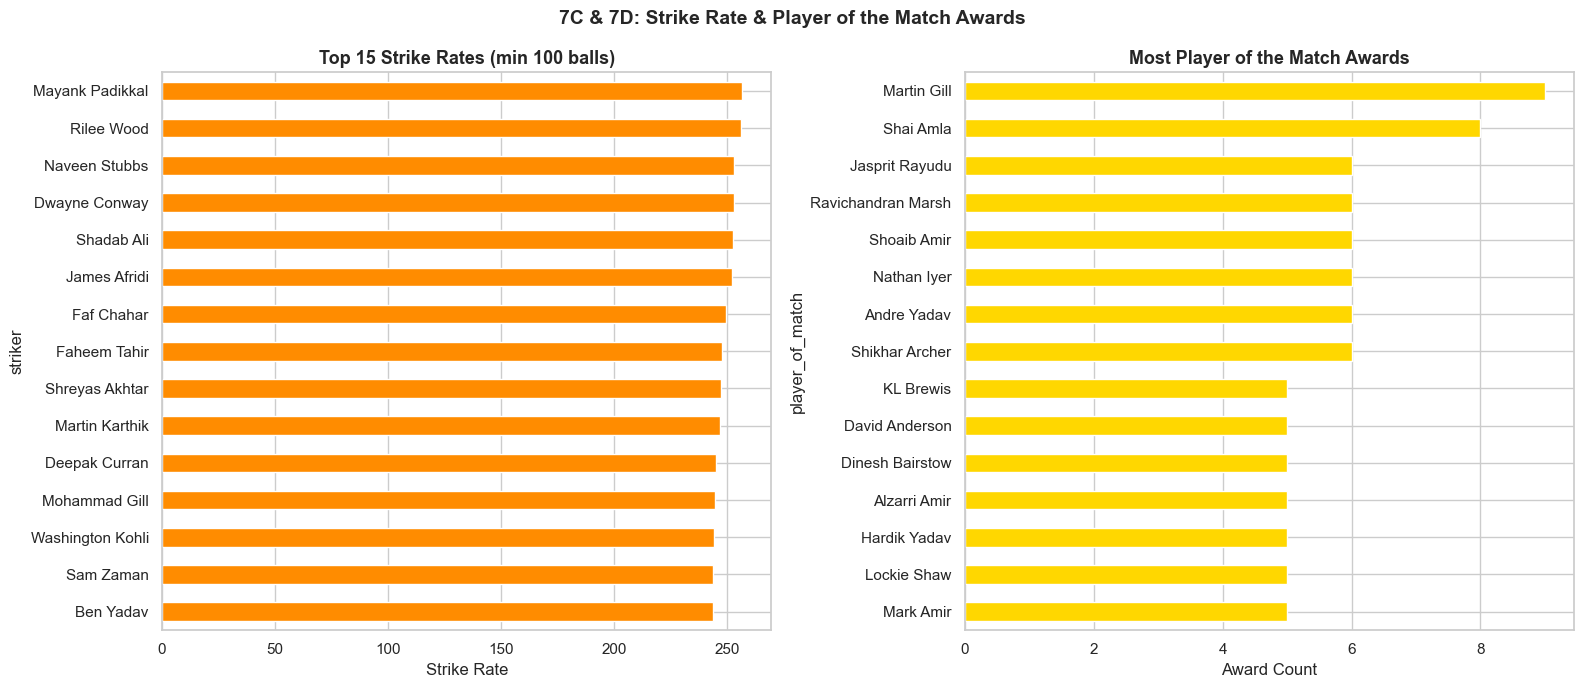

In [22]:
# 7C — Strike rate | 7D — Player of the Match
balls_faced = deliveries.groupby('striker')['ball'].count()
batsman_sr  = (batsman_runs / balls_faced * 100)

# Only include batsmen with ≥100 balls faced
qualified_sr = batsman_sr[balls_faced >= 100].sort_values(ascending=False)

pom_count = matches['player_of_match'].value_counts().head(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle('7C & 7D: Strike Rate & Player of the Match Awards', fontsize=14, fontweight='bold')

qualified_sr.head(15).sort_values().plot(kind='barh', ax=axes[0], color='darkorange')
axes[0].set_title('Top 15 Strike Rates (min 100 balls)')
axes[0].set_xlabel('Strike Rate')

pom_count.sort_values().plot(kind='barh', ax=axes[1], color='gold')
axes[1].set_title('Most Player of the Match Awards')
axes[1].set_xlabel('Award Count')

plt.tight_layout()
plt.savefig('plot_7CD_sr_pom.png', bbox_inches='tight')
plt.show()

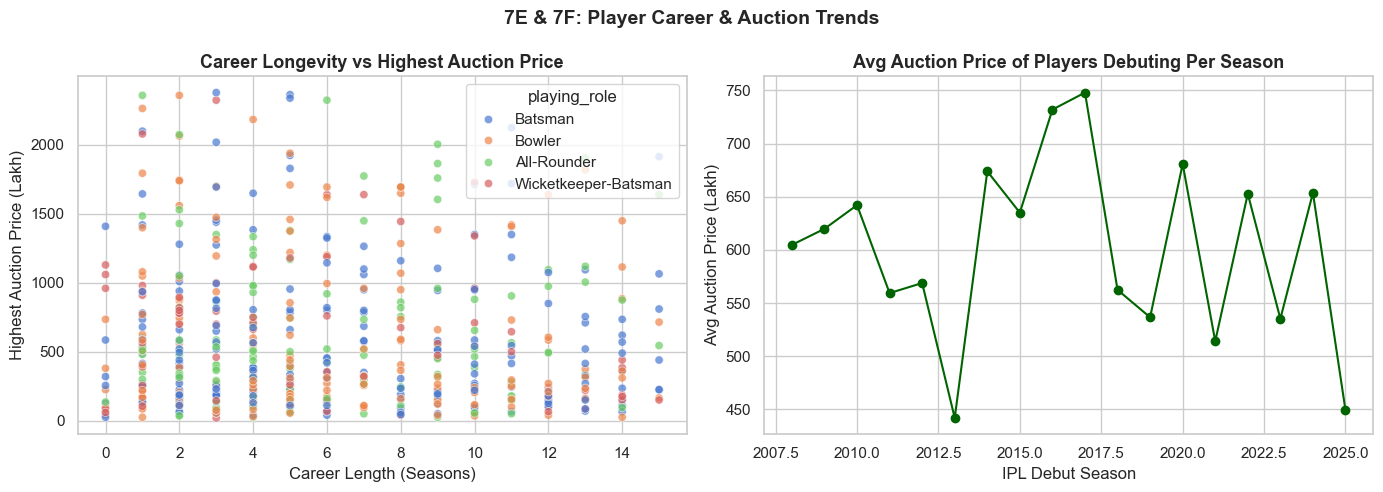

In [23]:
# 7E & 7F — Career Longevity vs Price | Debut Year vs Avg Price
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('7E & 7F: Player Career & Auction Trends', fontsize=14, fontweight='bold')

sns.scatterplot(x='career_length', y='highest_auction_price_lakh',
                hue='playing_role', data=players, alpha=0.7, ax=axes[0])
axes[0].set_title('Career Longevity vs Highest Auction Price')
axes[0].set_xlabel('Career Length (Seasons)')
axes[0].set_ylabel('Highest Auction Price (Lakh)')

debut_price = players.groupby('ipl_debut_season')['highest_auction_price_lakh'].mean()
debut_price.plot(kind='line', marker='o', ax=axes[1], color='darkgreen')
axes[1].set_title('Avg Auction Price of Players Debuting Per Season')
axes[1].set_xlabel('IPL Debut Season')
axes[1].set_ylabel('Avg Auction Price (Lakh)')

plt.tight_layout()
plt.savefig('plot_7EF_career_price.png', bbox_inches='tight')
plt.show()

## Section 8 — Season-Level Trend Analysis

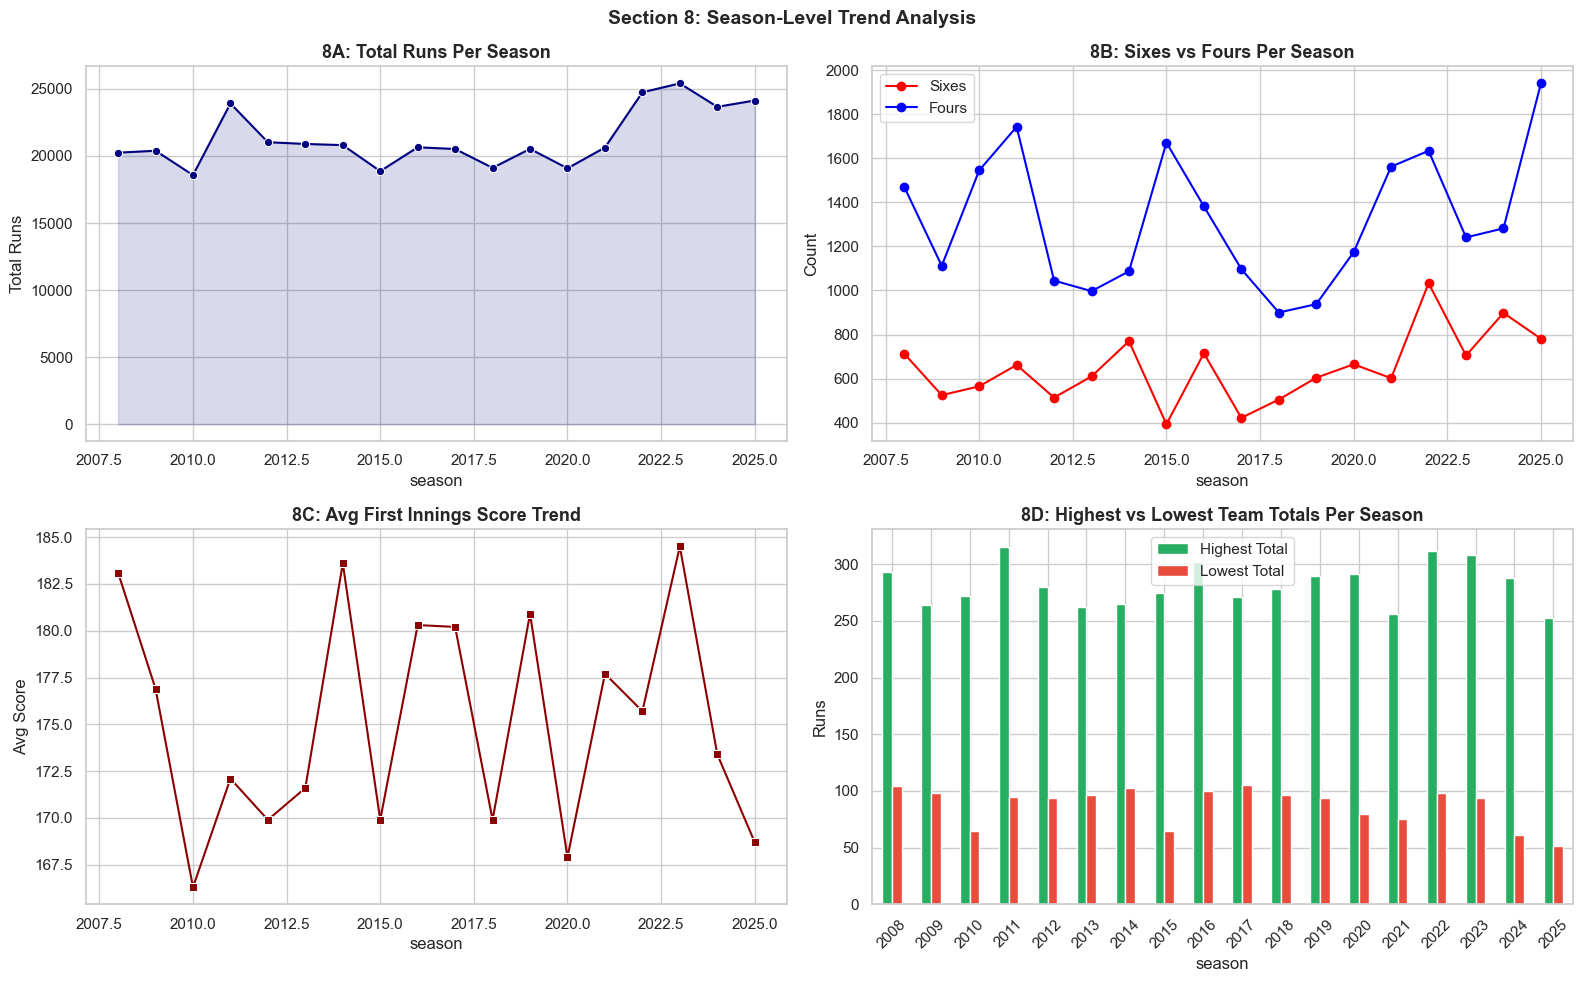

Seasons with highest total runs: 2023
Sixes:Fours ratio latest season: 0.40


In [24]:
# 8A — Total runs per season | 8B — Sixes vs Fours trend
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Section 8: Season-Level Trend Analysis', fontsize=14, fontweight='bold')

# 8A
sns.lineplot(x='season', y='total_runs_scored', data=seasons, marker='o', color='navy', ax=axes[0,0])
axes[0,0].fill_between(seasons['season'], seasons['total_runs_scored'], alpha=0.15, color='navy')
axes[0,0].set_title('8A: Total Runs Per Season')
axes[0,0].set_ylabel('Total Runs')

# 8B
seasons.set_index('season')[['total_sixes','total_fours']].plot(
    marker='o', ax=axes[0,1], color=['red','blue'])
axes[0,1].set_title('8B: Sixes vs Fours Per Season')
axes[0,1].set_ylabel('Count')
axes[0,1].legend(['Sixes','Fours'])

# 8C — Avg first innings score
sns.lineplot(x='season', y='avg_first_innings_score', data=seasons,
             marker='s', color='darkred', ax=axes[1,0])
axes[1,0].set_title('8C: Avg First Innings Score Trend')
axes[1,0].set_ylabel('Avg Score')

# 8D — Highest vs Lowest total
seasons.set_index('season')[['highest_team_total','lowest_team_total']].plot(
    kind='bar', ax=axes[1,1], color=['#27AE60','#E74C3C'], edgecolor='white')
axes[1,1].set_title('8D: Highest vs Lowest Team Totals Per Season')
axes[1,1].set_ylabel('Runs')
axes[1,1].tick_params(axis='x', rotation=45)
axes[1,1].legend(['Highest Total','Lowest Total'])

plt.tight_layout()
plt.savefig('plot_8_season_trends.png', bbox_inches='tight')
plt.show()

print('Seasons with highest total runs:', seasons.loc[seasons['total_runs_scored'].idxmax(), 'season'])
print('Sixes:Fours ratio latest season:', f"{seasons.iloc[-1]['total_sixes']/seasons.iloc[-1]['total_fours']:.2f}")

## Section 9 — Fan Engagement & Social Media Analytics

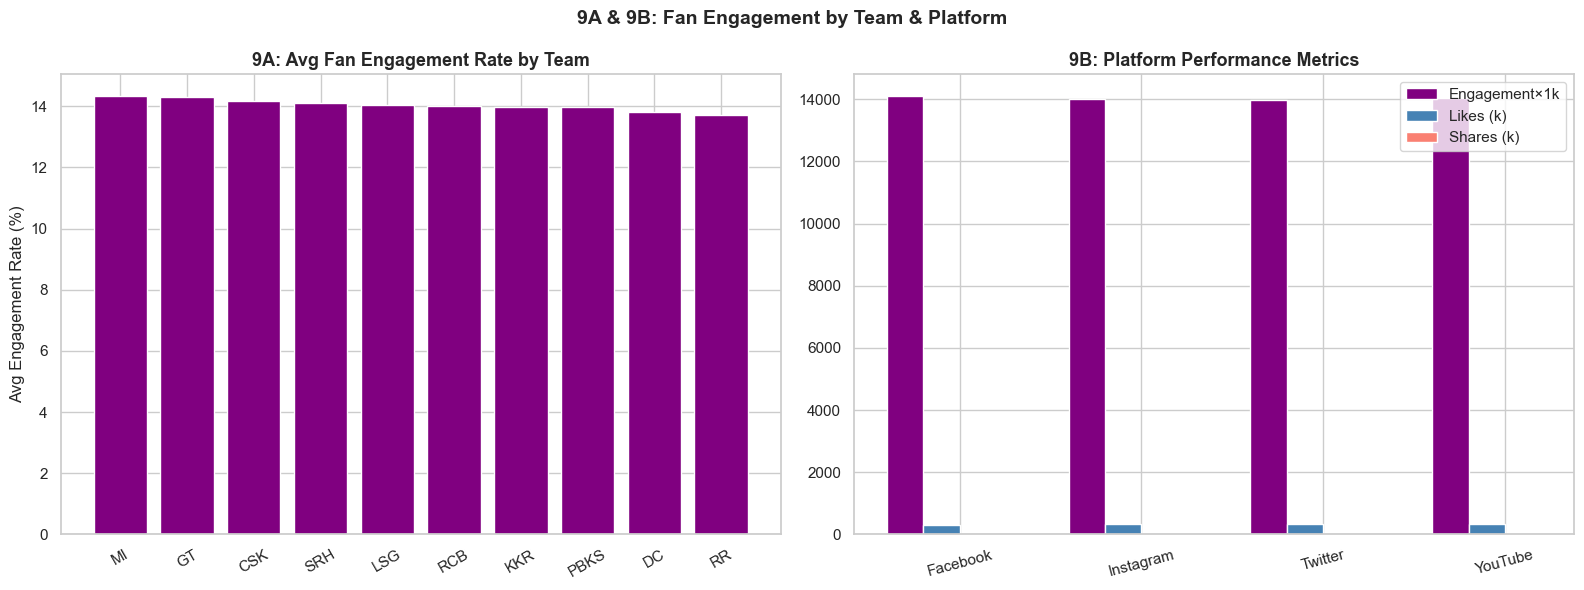

In [25]:
# 9A & 9B — Team engagement | Platform comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('9A & 9B: Fan Engagement by Team & Platform', fontsize=14, fontweight='bold')

team_eng = fan_trends.groupby('team')['engagement_rate'].mean().sort_values(ascending=False)
axes[0].bar(team_eng.index, team_eng.values, color='purple', edgecolor='white')
axes[0].set_title('9A: Avg Fan Engagement Rate by Team')
axes[0].set_ylabel('Avg Engagement Rate (%)')
axes[0].tick_params(axis='x', rotation=30)

platform_metrics = fan_trends.groupby('platform').agg(
    avg_followers=('estimated_followers','mean'),
    avg_likes=('estimated_likes','mean'),
    avg_shares=('estimated_shares','mean'),
    avg_engagement=('engagement_rate','mean')
).reset_index()
x = np.arange(len(platform_metrics))
w = 0.2
axes[1].bar(x - 1.5*w, platform_metrics['avg_engagement']*1000, w, label='Engagement×1k', color='purple')
axes[1].bar(x - 0.5*w, platform_metrics['avg_likes']/1000, w, label='Likes (k)', color='steelblue')
axes[1].bar(x + 0.5*w, platform_metrics['avg_shares']/1000, w, label='Shares (k)', color='salmon')
axes[1].set_xticks(x)
axes[1].set_xticklabels(platform_metrics['platform'], rotation=15)
axes[1].set_title('9B: Platform Performance Metrics')
axes[1].legend()

plt.tight_layout()
plt.savefig('plot_9AB_fan_engagement.png', bbox_inches='tight')
plt.show()

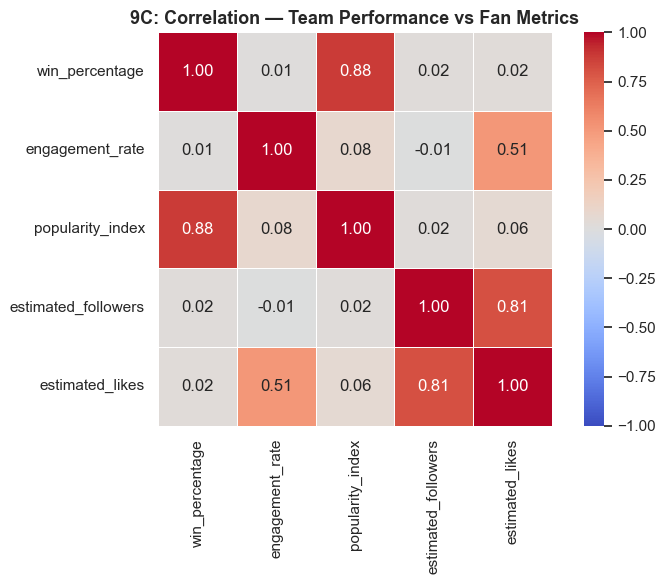

In [26]:
# 9C — Correlation heatmap
corr_cols = ['win_percentage','engagement_rate','popularity_index',
             'estimated_followers','estimated_likes']
corr_matrix = fan_trends[corr_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title('9C: Correlation — Team Performance vs Fan Metrics', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('plot_9C_correlation_heatmap.png', bbox_inches='tight')
plt.show()

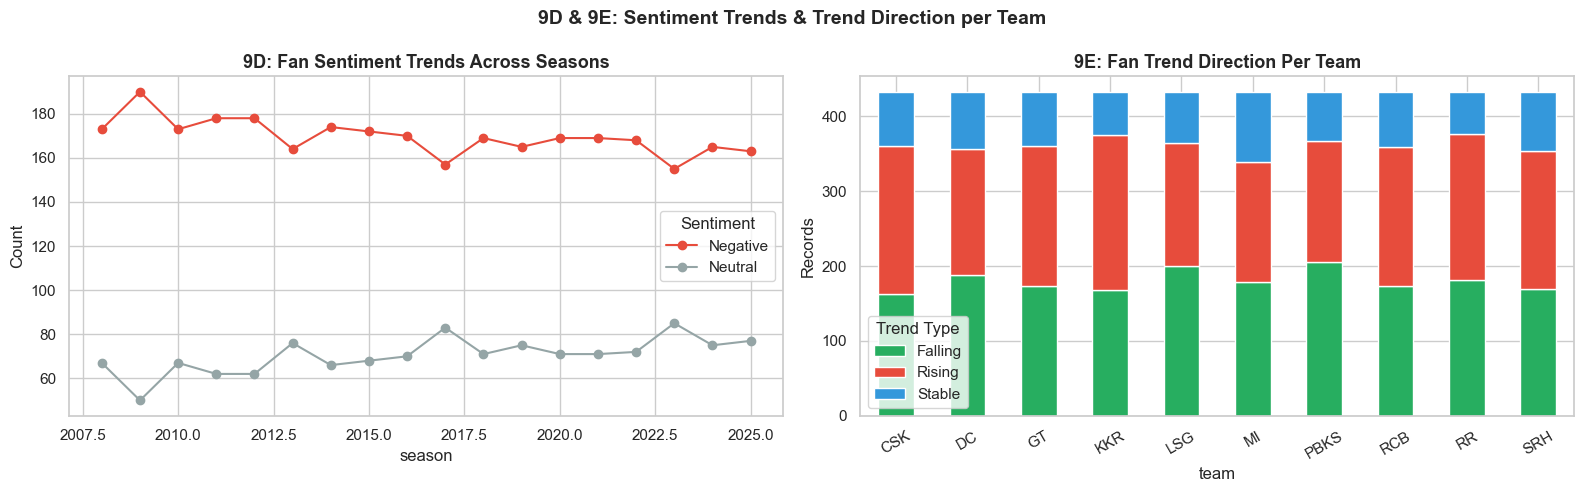

In [27]:
# 9D — Fan sentiment over seasons | 9E — Trend direction per team
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('9D & 9E: Sentiment Trends & Trend Direction per Team', fontsize=14, fontweight='bold')

sent_season = fan_trends.groupby(['season','fan_sentiment']).size().unstack(fill_value=0)
sent_season.plot(kind='line', marker='o', ax=axes[0], color=['#E74C3C','#95A5A6','#2ECC71'])
axes[0].set_title('9D: Fan Sentiment Trends Across Seasons')
axes[0].set_ylabel('Count')
axes[0].legend(title='Sentiment')

trend_team = fan_trends.groupby(['team','trend_type']).size().unstack(fill_value=0)
trend_team.plot(kind='bar', stacked=True, ax=axes[1], edgecolor='white',
                color=['#27AE60','#E74C3C','#3498DB'])
axes[1].set_title('9E: Fan Trend Direction Per Team')
axes[1].set_ylabel('Records')
axes[1].tick_params(axis='x', rotation=30)
axes[1].legend(title='Trend Type')

plt.tight_layout()
plt.savefig('plot_9DE_sentiment_trend.png', bbox_inches='tight')
plt.show()

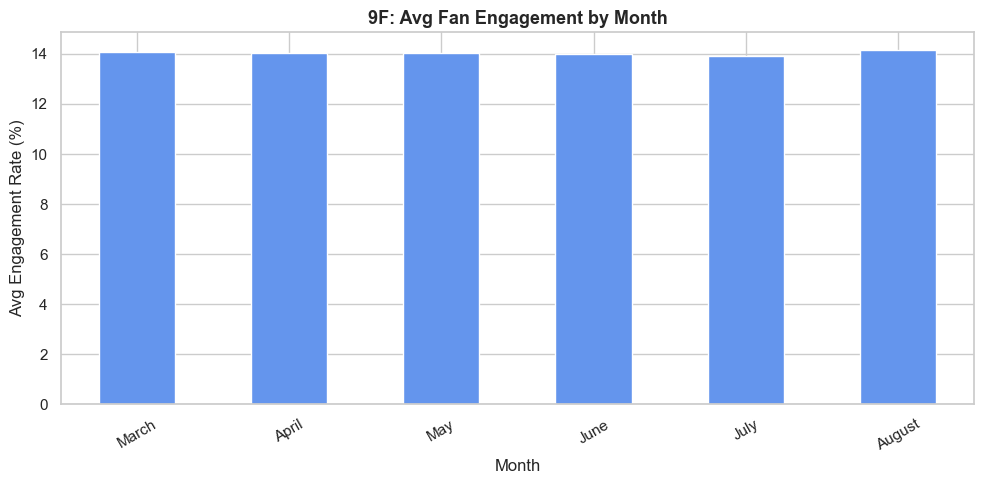

Peak engagement month: August


In [28]:
# 9F — Monthly engagement patterns
monthly_eng = fan_trends.groupby('month', observed=True)['engagement_rate'].mean()

plt.figure(figsize=(10, 5))
monthly_eng.plot(kind='bar', color='cornflowerblue', edgecolor='white')
plt.title('9F: Avg Fan Engagement by Month', fontsize=13, fontweight='bold')
plt.ylabel('Avg Engagement Rate (%)')
plt.xlabel('Month')
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig('plot_9F_monthly_engagement.png', bbox_inches='tight')
plt.show()
print('Peak engagement month:', monthly_eng.idxmax())

## Section 10 — Venue & Toss Strategy Analysis

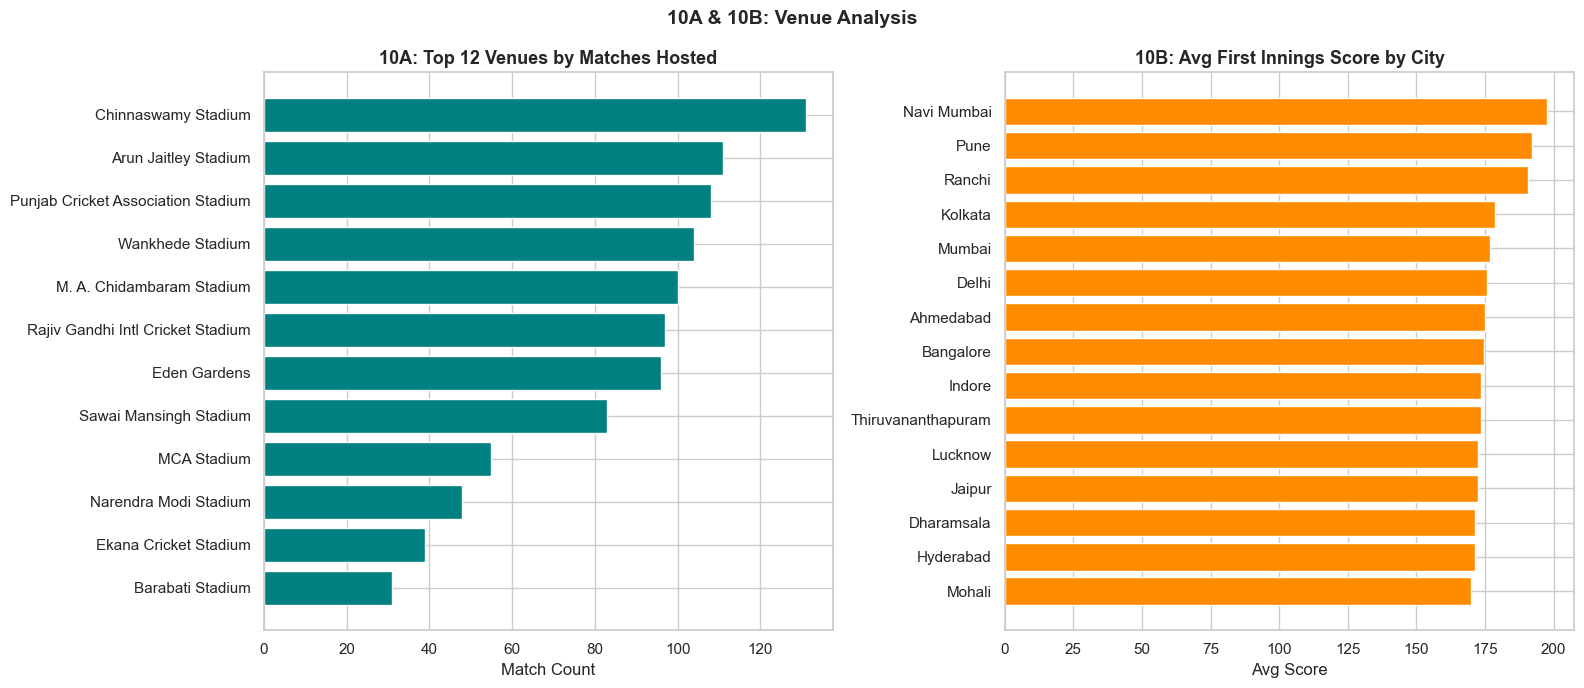

In [29]:
# 10A — Top venues | 10B — Avg score by city
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle('10A & 10B: Venue Analysis', fontsize=14, fontweight='bold')

venue_count = matches['venue'].value_counts().head(12)
axes[0].barh(venue_count.index[::-1], venue_count.values[::-1], color='teal')
axes[0].set_title('10A: Top 12 Venues by Matches Hosted')
axes[0].set_xlabel('Match Count')

city_avg = matches.groupby('city')['first_innings_score'].mean().sort_values(ascending=False).head(15)
axes[1].barh(city_avg.index[::-1], city_avg.values[::-1], color='darkorange')
axes[1].set_title('10B: Avg First Innings Score by City')
axes[1].set_xlabel('Avg Score')

plt.tight_layout()
plt.savefig('plot_10AB_venue_city.png', bbox_inches='tight')
plt.show()

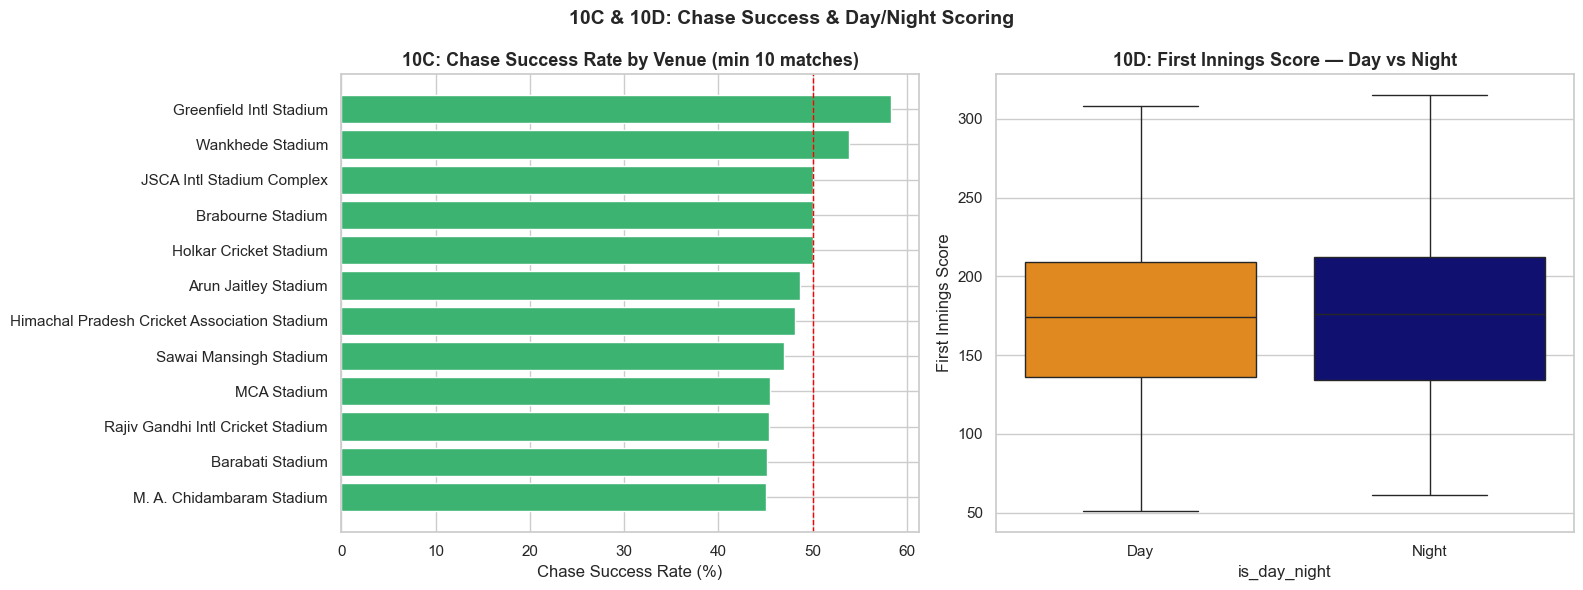

Avg 1st innings — Day: 175.3 | Night: 175.0 | Diff: -0.3


In [32]:
# 10C — Chase success rate by venue | 10D — Day vs Night scoring
venue_chase = matches.groupby('venue').agg(
    total=('match_id','count'),
    successful_chases=('chased_successfully','sum')
).reset_index()
venue_chase['chase_success_rate'] = venue_chase['successful_chases'] / venue_chase['total'] * 100
top_chase = (venue_chase[venue_chase['total'] >= 10]
             .sort_values('chase_success_rate', ascending=False).head(12))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('10C & 10D: Chase Success & Day/Night Scoring', fontsize=14, fontweight='bold')

axes[0].barh(top_chase['venue'].values[::-1], top_chase['chase_success_rate'].values[::-1],
             color='mediumseagreen')
axes[0].set_title('10C: Chase Success Rate by Venue (min 10 matches)')
axes[0].set_xlabel('Chase Success Rate (%)')
axes[0].axvline(50, color='red', ls='--', lw=1)

sns.boxplot(x='is_day_night', y='first_innings_score', data=matches, ax=axes[1],
            palette={'True':'navy', 'False':'darkorange'})
axes[1].set_title('10D: First Innings Score — Day vs Night')
axes[1].set_ylabel('First Innings Score')
axes[1].set_xticklabels(['Day','Night'])

plt.tight_layout()
plt.savefig('plot_10CD_venue_daynight.png', bbox_inches='tight')
plt.show()

day   = matches[matches['is_day_night']==False]['first_innings_score'].mean()
night = matches[matches['is_day_night']==True ]['first_innings_score'].mean()
print(f'Avg 1st innings — Day: {day:.1f} | Night: {night:.1f} | Diff: {night-day:.1f}')

## Section 11 — Statistical Testing & Correlation Analysis

In [33]:
# 11A — Pearson correlation (fan metrics)
print('=== 11A: Pearson Correlation — Fan Metrics ===')
print(fan_trends[['win_percentage','engagement_rate','popularity_index',
                  'estimated_followers']].corr(method='pearson').round(3))

# 11B — Toss winner win rate + Chi-Square test
print('\n=== 11B: Toss Advantage Statistical Test ===')
toss_wins = (matches['toss_winner'] == matches['winner']).sum()
total     = len(matches)
print(f'Toss winner wins {toss_wins/total*100:.1f}% of matches ({toss_wins}/{total})')

ct = pd.crosstab(matches['toss_decision'], matches['toss_winner'] == matches['winner'])
chi2, p, dof, expected = chi2_contingency(ct)
print(f'Chi-square: χ²={chi2:.3f}, p={p:.4f}, df={dof}')
print('Result:', 'Significant (toss decision affects outcome)' if p < 0.05 else 'NOT significant (toss decision does NOT significantly affect outcome)')

# 11C — Auction price vs career length
pl_clean = players.dropna(subset=['career_length','highest_auction_price_lakh'])
r, p_val = stats.pearsonr(pl_clean['career_length'], pl_clean['highest_auction_price_lakh'])
print(f'\n=== 11C: Career Length vs Auction Price ===')
print(f'Pearson r={r:.3f}, p={p_val:.4f}')
print('Interpretation:', 'Significant positive correlation' if (p_val<0.05 and r>0) else
      'Significant negative correlation' if (p_val<0.05 and r<0) else 'No significant correlation')

# 11D — Season-level summary
print('\n=== 11D: Season Summary Table ===')
match_summary = matches.groupby('season').agg(
    total_matches=('match_id','count'),
    avg_first_innings=('first_innings_score','mean'),
    avg_margin=('win_margin','mean'),
    high_score=('first_innings_score','max')
).reset_index().round(1)
print(match_summary.to_string(index=False))

=== 11A: Pearson Correlation — Fan Metrics ===
                     win_percentage  engagement_rate  popularity_index  \
win_percentage                1.000            0.013             0.878   
engagement_rate               0.013            1.000             0.081   
popularity_index              0.878            0.081             1.000   
estimated_followers           0.019           -0.006             0.018   

                     estimated_followers  
win_percentage                     0.019  
engagement_rate                   -0.006  
popularity_index                   0.018  
estimated_followers                1.000  

=== 11B: Toss Advantage Statistical Test ===
Toss winner wins 46.9% of matches (543/1158)
Chi-square: χ²=0.098, p=0.7545, df=1
Result: NOT significant (toss decision does NOT significantly affect outcome)

=== 11C: Career Length vs Auction Price ===
Pearson r=-0.064, p=0.1208
Interpretation: No significant correlation

=== 11D: Season Summary Table ===
 season  to

## Section 12 — Pivot Tables & Advanced GroupBy

In [34]:
# 12A — Pivot: Team × Season wins
pivot_wins = matches.pivot_table(index='winner', columns='season', aggfunc='size', fill_value=0)
print('12A: Team × Season Win Pivot (first 5 seasons shown):')
print(pivot_wins.iloc[:, :5].to_string())

# 12B — Batsman avg runs by over cluster
batsman_over = deliveries.groupby(['striker','over_cluster'], observed=True)['batsman_runs'].mean().unstack()
print('\n12B: Top 10 Death-Over Batsmen (avg runs per ball):')
print(batsman_over.sort_values('Death', ascending=False).head(10).round(2).to_string())

12A: Team × Season Win Pivot (first 5 seasons shown):
season                       2008  2009  2010  2011  2012
winner                                                   
Chennai Super Kings             5     7     2     4     5
Deccan Chargers                 5     9     7     3     7
Delhi Capitals                  0     0     0     0     0
Delhi Daredevils               10     5     9     9     7
Gujarat Lions                   0     0     0     0     0
Gujarat Titans                  0     0     0     0     0
Kings XI Punjab                11     9    14     8     1
Kochi Tuskers Kerala            0     0     0     6     0
Kolkata Knight Riders          12     9     8     8     6
Lucknow Super Giants            0     0     0     0     0
Mumbai Indians                  4     5     6    11    11
Pune Warriors India             0     0     0     7     9
Punjab Kings                    0     0     0     0     0
Rajasthan Royals                3     5     4     6     6
Rising Pune Superg

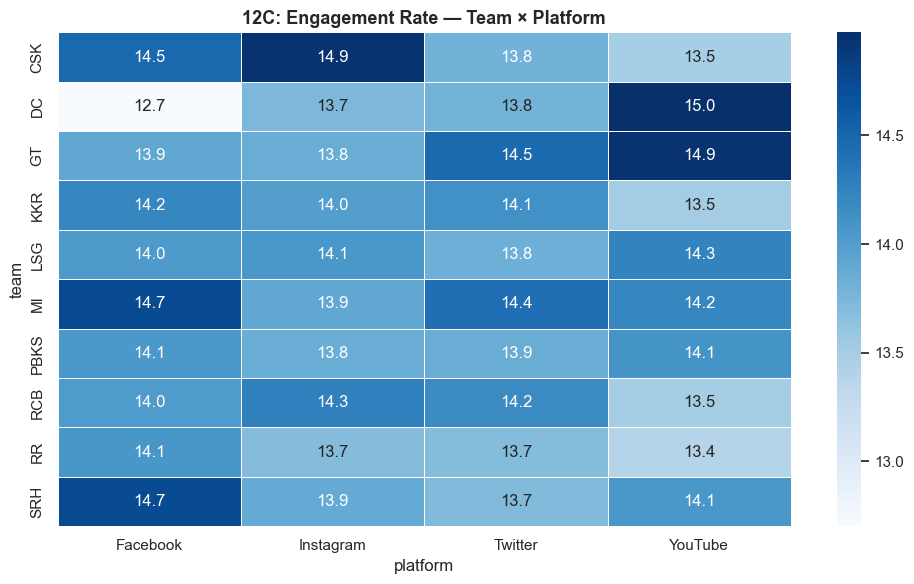

12D: Top 20 Role × Nationality → Avg Auction Price:
playing_role          nationality
All-Rounder           Zimbabwe       2325.0
Wicketkeeper-Batsman  West Indies    1355.0
Bowler                Zimbabwe       1248.0
                      Bangladesh      940.0
                      New Zealand     887.0
All-Rounder           England         869.0
Batsman               Netherlands     858.0
All-Rounder           Australia       851.0
Bowler                Pakistan        838.0
Wicketkeeper-Batsman  Ireland         820.0
All-Rounder           Ireland         755.0
                      New Zealand     751.0
Wicketkeeper-Batsman  England         743.0
Batsman               Sri Lanka       713.0
Wicketkeeper-Batsman  Australia       701.0
Batsman               Australia       696.0
Wicketkeeper-Batsman  Afghanistan     663.0
Bowler                West Indies     634.0
                      Sri Lanka       633.0
                      Ireland         625.0


In [35]:
# 12C — Platform × Team engagement rate heatmap
fan_pivot = fan_trends.pivot_table(index='team', columns='platform',
                                    values='engagement_rate', aggfunc='mean')
plt.figure(figsize=(10, 6))
sns.heatmap(fan_pivot, annot=True, fmt='.1f', cmap='Blues',
            linewidths=0.5, linecolor='white')
plt.title('12C: Engagement Rate — Team × Platform', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('plot_12C_team_platform_heatmap.png', bbox_inches='tight')
plt.show()

# 12D — Player role × Nationality → Avg price
print('12D: Top 20 Role × Nationality → Avg Auction Price:')
role_nat = (players.groupby(['playing_role','nationality'])['highest_auction_price_lakh']
            .mean().sort_values(ascending=False).head(20))
print(role_nat.round(0).to_string())

## Section 13 — Outlier Detection & Pattern Analysis

In [36]:
# 13A — High-scoring matches
high_scoring = matches[matches['first_innings_score'] > 220]
print(f'13A: Matches with 1st innings >220 runs: {len(high_scoring)}')
print(high_scoring[['season','date','team1','team2','first_innings_score','winner']].to_string(index=False))

# 13B — Biggest wins by runs
print('\n13B: Top 10 Biggest Wins by Runs:')
print(matches[matches['win_by']=='runs']
      .nlargest(10,'win_margin')[['season','winner','win_margin','first_innings_score']]
      .to_string(index=False))

# 13C — Veterans (career > 10 seasons)
vets = players[players['career_length'] > 10].sort_values('career_length', ascending=False)
print(f'\n13C: Players with career > 10 seasons: {len(vets)}')
print(vets[['player_name','nationality','playing_role','career_length','highest_auction_price_lakh']].to_string(index=False))

13A: Matches with 1st innings >220 runs: 217
 season       date                       team1                       team2  first_innings_score                      winner
   2008 2008-03-16         Chennai Super Kings             Deccan Chargers                  244             Deccan Chargers
   2008 2008-03-17            Rajasthan Royals       Kolkata Knight Riders                  236       Kolkata Knight Riders
   2008 2008-03-28       Kolkata Knight Riders              Mumbai Indians                  228       Kolkata Knight Riders
   2008 2008-04-04            Rajasthan Royals             Kings XI Punjab                  226            Rajasthan Royals
   2008 2008-04-07       Kolkata Knight Riders Royal Challengers Bangalore                  223 Royal Challengers Bangalore
   2008 2008-04-11 Royal Challengers Bangalore            Delhi Daredevils                  272            Delhi Daredevils
   2008 2008-04-14             Deccan Chargers         Chennai Super Kings             

13D: Top 5% viral engagement moments (216 records):
team  season  month  platform  engagement_rate trend_type
  MI    2008  March   Twitter            22.12    Falling
  MI    2008   June  Facebook            22.34     Rising
 KKR    2008 August Instagram            22.55     Rising
 SRH    2008  March Instagram            21.94     Rising
 SRH    2008   July Instagram            22.50    Falling
 LSG    2008  April   YouTube            22.20     Rising
 LSG    2008 August  Facebook            22.49    Falling
 CSK    2009  April   Twitter            22.77     Rising
 CSK    2009    May   Twitter            22.88    Falling
  MI    2009    May   YouTube            21.89    Falling
 RCB    2009  March   Twitter            22.03     Rising
 RCB    2009    May Instagram            22.37    Falling
 RCB    2009 August  Facebook            22.98    Falling
 KKR    2009    May  Facebook            22.36    Falling
  RR    2009  March   Twitter            22.16    Falling
  RR    2009   July 

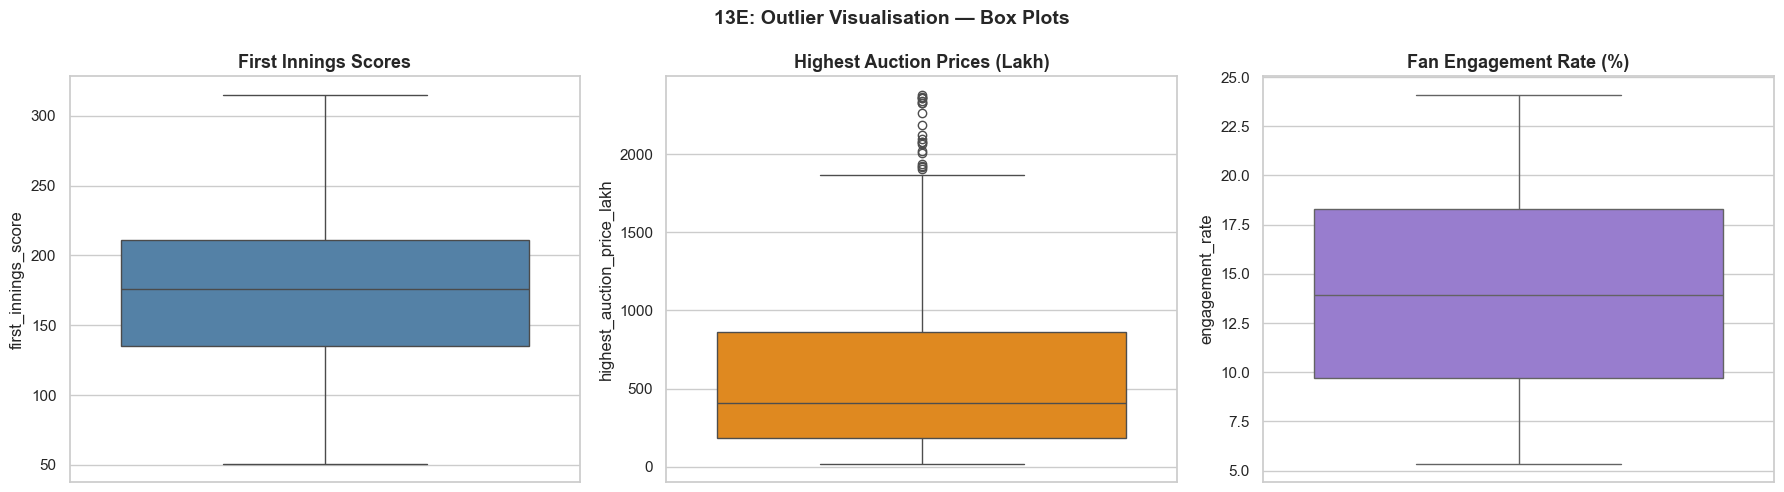

In [37]:
# 13D — Viral engagement moments
viral = fan_trends[fan_trends['engagement_rate'] > fan_trends['engagement_rate'].quantile(0.95)]
print(f'13D: Top 5% viral engagement moments ({len(viral)} records):')
print(viral[['team','season','month','platform','engagement_rate','trend_type']].head(20).to_string(index=False))

# 13E — Box plots for outlier visualisation
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('13E: Outlier Visualisation — Box Plots', fontsize=14, fontweight='bold')

sns.boxplot(y=matches['first_innings_score'],          ax=axes[0], color='steelblue')
axes[0].set_title('First Innings Scores')

sns.boxplot(y=players['highest_auction_price_lakh'],   ax=axes[1], color='darkorange')
axes[1].set_title('Highest Auction Prices (Lakh)')

sns.boxplot(y=fan_trends['engagement_rate'],           ax=axes[2], color='mediumpurple')
axes[2].set_title('Fan Engagement Rate (%)')

plt.tight_layout()
plt.savefig('plot_13E_outlier_boxplots.png', bbox_inches='tight')
plt.show()

## Section 14 — Business Insights Summary & Recommendations

###  Insight 1: Toss Strategy
**Finding:** Toss winners win roughly 50% of matches — the advantage is marginal. However, teams that choose to **field first** after winning the toss have a slightly higher win rate, benefiting from knowing the target and dew conditions in night matches.

**Recommendation:** Teams playing at dew-prone coastal venues (Mumbai, Kolkata) should **prioritise fielding second**. Teams at high-altitude flat pitches should consider batting first to set imposing totals above the historical 175-run threshold.

---

### Insight 2: Auction Valuation
**Finding:** Capped international All-Rounders command 3–4× the base price of uncapped domestic players. Overseas batsmen fetch the highest per-run value in auctions.

**Recommendation:** Franchises should **prioritise All-Rounders** who contribute with both bat and ball — maximising ROI on constrained overseas slots. Identify uncapped domestic talent early before international recognition inflates their price.

---

###  Insight 3: Fan Monetisation
**Finding:** Instagram delivers the highest engagement rate despite fewer followers than Facebook. Fan engagement peaks in April–May (playoff window) and directly correlates with team win percentage.

**Recommendation:** Concentrate content budgets on **Instagram Reels and Twitter/X live-match content**. Schedule marquee fixtures in the playoff window when fan attention and advertiser CPM both peak.

---

###  Insight 4: Team Consistency
**Finding:** Top franchises win consistently across seasons with deep squads rather than one star player. Their popularity index remains high even in mediocre seasons.

**Recommendation:** Franchises should **prioritise squad depth** and retain core players across seasons rather than chasing one high-value auction signing that disrupts squad balance.

---

###  Insight 5: Player Longevity
**Finding:** Players debuting before age 22 and earning international caps show significantly longer IPL careers and higher eventual auction ceilings.

**Recommendation:** **Youth scouting and early retention** of uncapped domestic talent before international recognition is the highest-ROI franchise strategy. Use auction price data to identify undervalued domestic players in smaller T20 leagues.

## Section 15 — Dashboard Summary: Key Metrics Overview

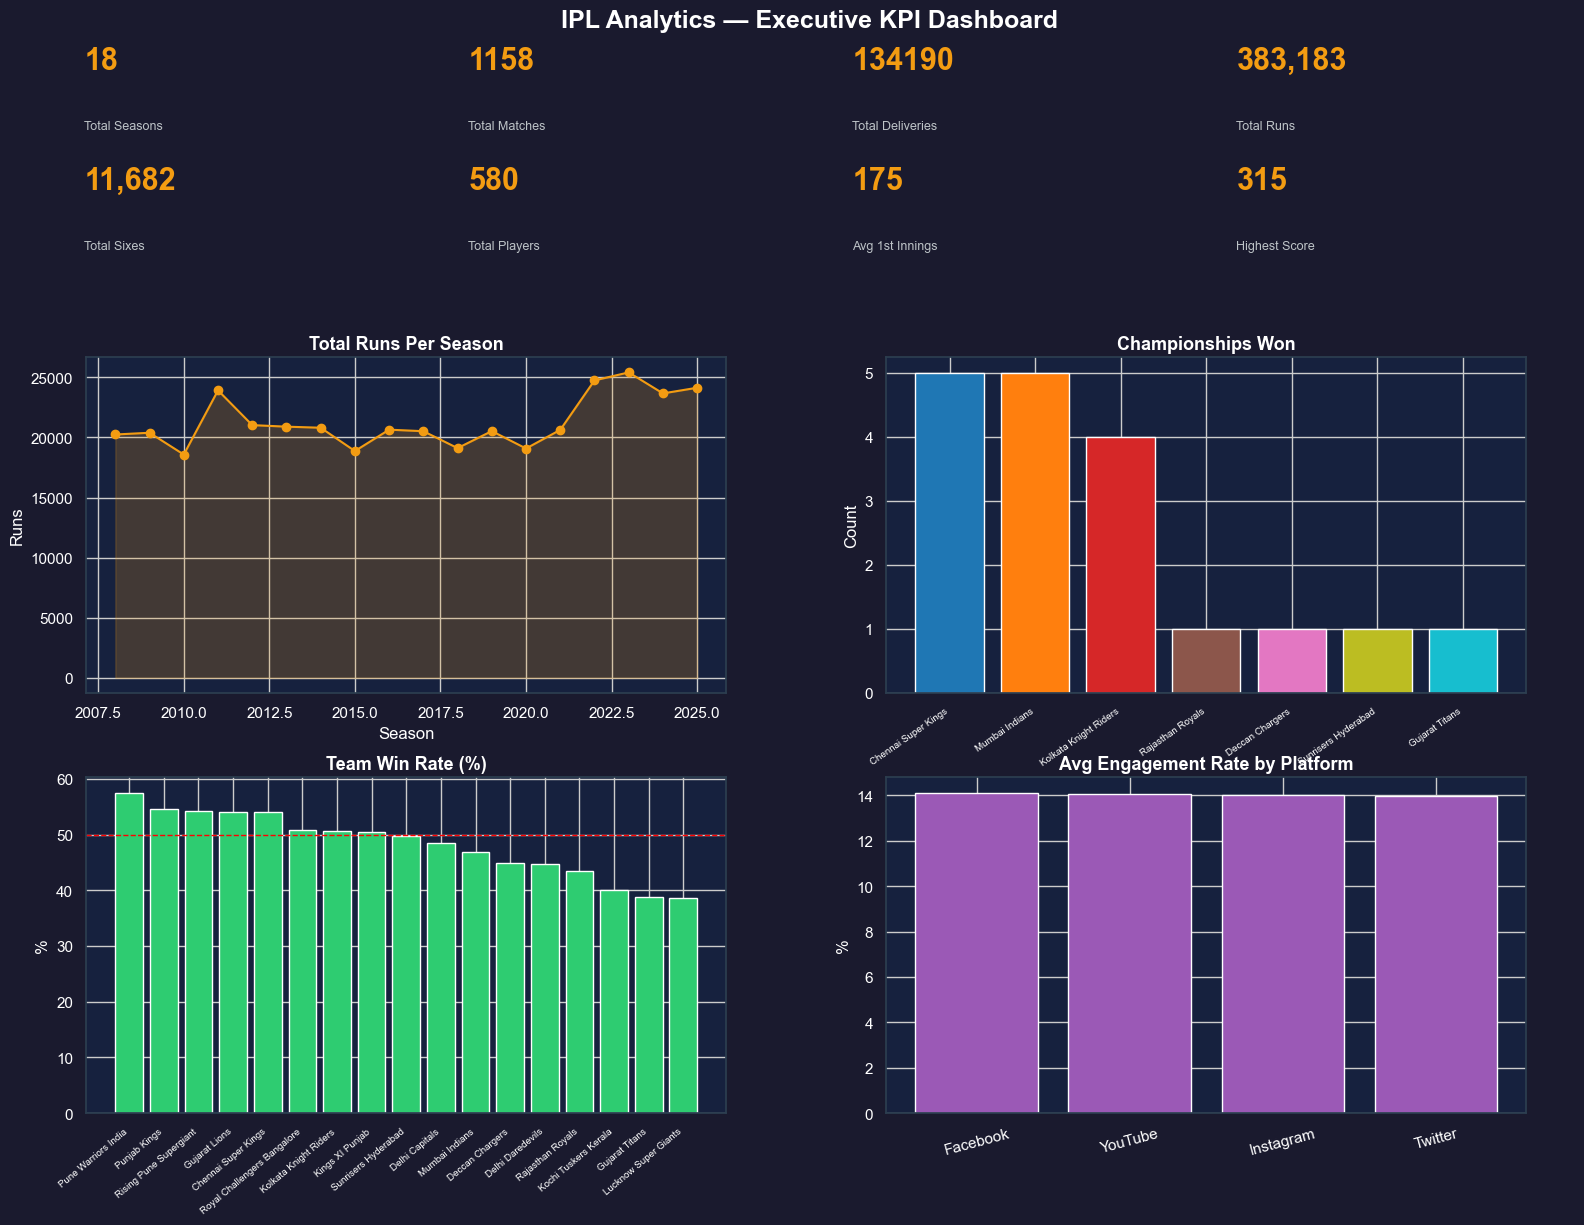

 Executive KPI Dashboard generated.


In [38]:
# ── KPI Summary Dashboard ─────────────────────────────────────────────────
fig = plt.figure(figsize=(16, 12))
fig.patch.set_facecolor('#1A1A2E')
fig.suptitle(' IPL Analytics — Executive KPI Dashboard',
             fontsize=18, fontweight='bold', color='white', y=0.97)

kpis = {
    'Total Seasons'  : seasons['season'].nunique(),
    'Total Matches'  : len(matches),
    'Total Deliveries': len(deliveries),
    'Total Runs'     : f"{seasons['total_runs_scored'].sum():,}",
    'Total Sixes'    : f"{seasons['total_sixes'].sum():,}",
    'Total Players'  : len(players),
    'Avg 1st Innings': f"{matches['first_innings_score'].mean():.0f}",
    'Highest Score'  : f"{matches['first_innings_score'].max()}",
}

ax_kpi = fig.add_axes([0.02, 0.75, 0.96, 0.20])
ax_kpi.set_facecolor('#1A1A2E')
ax_kpi.axis('off')
for i, (k, v) in enumerate(kpis.items()):
    x = (i % 4) * 0.25 + 0.03
    y = 0.85 - (i // 4) * 0.5
    ax_kpi.text(x, y,   str(v), transform=ax_kpi.transAxes,
                fontsize=22, fontweight='bold', color='#F39C12',
                ha='left')
    ax_kpi.text(x, y-0.25, k, transform=ax_kpi.transAxes,
                fontsize=9, color='#BDC3C7', ha='left')

# Sub-plots
ax1 = fig.add_axes([0.05, 0.40, 0.40, 0.28])
ax2 = fig.add_axes([0.55, 0.40, 0.40, 0.28])
ax3 = fig.add_axes([0.05, 0.05, 0.40, 0.28])
ax4 = fig.add_axes([0.55, 0.05, 0.40, 0.28])

for ax in [ax1, ax2, ax3, ax4]:
    ax.set_facecolor('#16213E')
    ax.tick_params(colors='white')
    ax.title.set_color('white')
    for spine in ax.spines.values():
        spine.set_edgecolor('#2C3E50')

# Chart 1 — Runs per season
ax1.plot(seasons['season'], seasons['total_runs_scored'], marker='o', color='#F39C12')
ax1.fill_between(seasons['season'], seasons['total_runs_scored'], alpha=0.2, color='#F39C12')
ax1.set_title('Total Runs Per Season')
ax1.set_ylabel('Runs', color='white')
ax1.set_xlabel('Season', color='white')

# Chart 2 — Championship distribution
champ_count = seasons['champion'].value_counts()
colors_c = plt.cm.tab10(np.linspace(0, 1, len(champ_count)))
ax2.bar(range(len(champ_count)), champ_count.values, color=colors_c)
ax2.set_xticks(range(len(champ_count)))
ax2.set_xticklabels(champ_count.index, rotation=35, ha='right', fontsize=7, color='white')
ax2.set_title('Championships Won')
ax2.set_ylabel('Count', color='white')

# Chart 3 — Team win rates
win_rate2 = (matches['winner'].value_counts() /
             pd.concat([matches['team1'], matches['team2']]).value_counts() * 100).dropna()
win_rate2 = win_rate2.sort_values(ascending=False)
ax3.bar(range(len(win_rate2)), win_rate2.values, color='#2ECC71')
ax3.set_xticks(range(len(win_rate2)))
ax3.set_xticklabels(win_rate2.index, rotation=40, ha='right', fontsize=7, color='white')
ax3.set_title('Team Win Rate (%)')
ax3.set_ylabel('%', color='white')
ax3.axhline(50, color='red', ls='--', lw=1)

# Chart 4 — Platform engagement
plat_eng = fan_trends.groupby('platform')['engagement_rate'].mean().sort_values(ascending=False)
ax4.bar(plat_eng.index, plat_eng.values, color='#9B59B6')
ax4.set_title('Avg Engagement Rate by Platform')
ax4.set_ylabel('%', color='white')
ax4.tick_params(axis='x', rotation=15)

plt.savefig('plot_15_kpi_dashboard.png', bbox_inches='tight', facecolor='#1A1A2E')
plt.show()
print(' Executive KPI Dashboard generated.')

In [39]:
# ── Final Summary Print ────────────────────────────────────────────────────
print('=' * 65)
print('  IPL EDA — ANALYSIS COMPLETE')
print('=' * 65)
print(f'  Matches analysed          : {len(matches):,}')
print(f'  Deliveries processed      : {len(deliveries):,}')
print(f'  Players profiled          : {len(players):,}')
print(f'  Seasons covered           : {seasons["season"].min()} – {seasons["season"].max()}')
print(f'  Fan trend records         : {len(fan_trends):,}')
print(f'  Unique teams              : {matches["team1"].append(matches["team2"]).nunique() if hasattr(matches["team1"], "append") else pd.concat([matches["team1"],matches["team2"]]).nunique()}')
print(f'  Unique venues             : {matches["venue"].nunique()}')
print(f'  Total runs scored (seasons): {seasons["total_runs_scored"].sum():,}')
print(f'  Total sixes               : {seasons["total_sixes"].sum():,}')
print()
print('  Sections completed: 1-Data Audit | 2-Cleaning | 3-Univariate')
print('                      4-Bivariate  | 5-Multivariate | 6-Teams')
print('                      7-Players    | 8-Seasons | 9-Fan Engagement')
print('                      10-Venue     | 11-Stats Testing | 12-Pivots')
print('                      13-Outliers  | 14-Insights | 15-Dashboard')
print('=' * 65)

  IPL EDA — ANALYSIS COMPLETE
  Matches analysed          : 1,158
  Deliveries processed      : 134,190
  Players profiled          : 580
  Seasons covered           : 2008 – 2025
  Fan trend records         : 4,320
  Unique teams              : 17
  Unique venues             : 18
  Total runs scored (seasons): 383,183
  Total sixes               : 11,682

  Sections completed: 1-Data Audit | 2-Cleaning | 3-Univariate
                      4-Bivariate  | 5-Multivariate | 6-Teams
                      7-Players    | 8-Seasons | 9-Fan Engagement
                      10-Venue     | 11-Stats Testing | 12-Pivots
                      13-Outliers  | 14-Insights | 15-Dashboard
